# Лекция 4: стриминг и регуляризация L1, L2, Elastic Net

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

Лекция 4 (`docs/20_10_26_PREL_4_STREAMING`) задаёт вопрос: *«Как научиться слушать то, что ещё не сказано?»* — то есть как модель должна работать, когда данные приходят потоком. Главный инструмент лекции — **регуляризация** логистической регрессии в трёх «ролях»:

| Роль в лекции | Метод | Штраф | Ожидаемое поведение |
|---|---|---|---|
| «Скульптор-минималист» | **L1 (Lasso)** | $\lambda\sum_j \lvert w_j\rvert$ | обнуляет часть коэффициентов → отбор признаков, быстро |
| «Художник-педант» | **L2 (Ridge)** | $\lambda\sum_j w_j^2$ | уменьшает все коэффициенты, но не обнуляет → устойчиво |
| «Режиссёр-адаптер» | **Elastic Net** | $\lambda\big(\alpha\lVert w\rVert_1 + (1-\alpha)\lVert w\rVert_2^2\big)$ | баланс; $\alpha$ сдвигает к L1 или к L2 |

В `scikit-learn` сила штрафа задаётся обратным параметром **C** (малое C = сильная регуляризация), а доля L1 — параметром **α = `l1_ratio`**.

**Три типа обработки данных (из лекции) и где в них наша система:**

| Тип | Как работает | Задержка | У нас |
|---|---|---|---|
| Пакетная (batch) | собираем всё, обрабатываем потом | минуты–часы | обучение модели на 2015–2022 из хранилища PostgreSQL |
| Микропакетная (micro-batch, Spark Structured Streaming) | маленькие пакеты каждые N секунд | секунды | **переобучение** модели раз в месяц / неделю на накопленной истории (часть III) |
| Потоковая в реальном времени (Kafka, Flink) | каждая запись сразу | миллисекунды | **прогноз** по каждой новой суточной записи (ноутбук 04, здесь — замер латентности) |

**План ноутбука — по частям лекции, но на наших данных** (Кишинёв, 26 признаков, цель — осадки завтра; обучение 2015–2022, валидация 2023, тест 2024–2025):

| Часть | Лекция | Что делаем |
|---|---|---|
| I | «Знакомство с актёрами» (`elastic_net_trio_1.py`) | L1, L2, ENet: коэффициенты, F1, латентность; сравнение с Random Forest |
| II | «Адаптивность» (`elastic_net_adaptiv_trio.py`) | перебор C и α, карты коэффициентов, таблица «C мал / велик, α мал / велик», выбор по валидации |
| III | «Стриминг» (`elastic_net_streaming_trio.py`) | коэффициенты во времени при переобучении потока 2024–2025, F1 и латентность в потоке, устойчивость (variance), шум датчиков и «адаптивный режиссёр» |
| IV | «Вишенка на торте» (`elastic_net_shap_trio.py`) | SHAP (`LinearExplainer`) против коэффициентов, общий график важности |
| V | мультиклассовая задача (конец лекции) | тип погоды завтра (3 класса): мультиномиальная регрессия + SHAP по классам |
| — | вопросы лекции | ответы, таблица сценариев «кому доверить поток», рефлексия |

**Примечание о коде.** В скриптах лекции метод задаётся параметром `penalty="l1" / "l2" / "elasticnet"`. В установленной версии `scikit-learn` 1.9 этот параметр устарел (будет удалён в 1.10), поэтому используется равнозначная запись `l1_ratio = 1 / 0 / 0.5` (решатель `saga`, как в лекции). Признаки стандартизируются: штраф одинаков для всех коэффициентов, поэтому признаки должны быть в одном масштабе (иначе давление в гПа «штрафовалось» бы иначе, чем доля солнечного сияния). Используется `class_weight="balanced"`, как во всём проекте (дождь — ~24 % дней).

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_dataset, load_daily
from features import FEATURES, FEATURE_NAMES_RU, TARGET, TARGET3, WEATHER_TYPES, build_features
from regularization import (METHODS, METHOD_COLORS, NOISY_SENSORS, SENSOR_NAMES_RU, make_model, coefficients, fit_timed,
                            predict_latency_ms, add_sensor_noise, noise_index, stream_retrain)
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, recall_score, precision_score

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
SEED = 42
RU = [FEATURE_NAMES_RU[f] for f in FEATURES]
GRID = np.round(np.arange(0.05, 0.95, 0.01), 2)

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

def best_threshold(y, p):
    return float(GRID[int(np.argmax([f1_score(y, p >= g) for g in GRID]))])

raw = load_daily("chisinau")
data = load_dataset("chisinau")
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024].reset_index(drop=True)
X_tr, y_tr, X_va, y_va, X_te, y_te = train[FEATURES], train[TARGET], valid[FEATURES], valid[TARGET], test[FEATURES], test[TARGET].to_numpy()
bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rf, THR_RF = bundle["model"], bundle["threshold"]
print(f"Обучение {len(train)} дней, валидация {len(valid)}, тест {len(test)}; эталон — {bundle['model_name']} (порог {THR_RF:.2f})")

Обучение 2916 дней, валидация 365, тест 730; эталон — Random Forest (порог 0.23)


---
# I. Знакомство с «актёрами»: L1, L2 и Elastic Net на наших данных

Как в `elastic_net_trio_1.py`: обучаем три модели и смотрим **коэффициенты, F1 и латентность**. Латентность меряем двумя способами, потому что в потоке важны оба:
- **обучение** — сколько стоит переобучить модель на пакете (здесь — 8 лет, 2 916 дней);
- **прогноз одной записи** — сколько ждёт каждая новая суточная запись (медиана по 300 вызовам).

Берём две силы регуляризации: **C = 1** (значение по умолчанию, как в скриптах лекции) и **C = 0.01** (сильный штраф). F1 — при пороге 0.5, без подбора (как в лекции). Для сравнения — наш Random Forest из ноутбука 02 с рабочим порогом 0.23.

In [2]:
rows, models_I = [], {}
for C in [1.0, 0.01]:
    for m_name, r in METHODS.items():
        m, fit_ms = fit_timed(make_model(C, r), X_tr, y_tr, repeats=3)
        p = m.predict_proba(X_te)[:, 1]
        models_I[(C, m_name)] = m
        rows.append({"C": C, "Метод": m_name, "ROC-AUC": roc_auc_score(y_te, p), "PR-AUC": average_precision_score(y_te, p),
                     "F1 (порог 0.5)": f1_score(y_te, p >= 0.5), "Recall": recall_score(y_te, p >= 0.5),
                     "Ненулевых коэф. из 26": int((np.abs(coefficients(m)) > 1e-10).sum()),
                     "Обучение, мс": fit_ms, "Прогноз 1 записи, мс": predict_latency_ms(m, X_te)})
p_rf = rf.predict_proba(X_te)[:, 1]
rf1 = clone(rf).set_params(n_jobs=1)
_, rf_fit = fit_timed(rf1, X_tr, y_tr)
rows.append({"C": "—", "Метод": "Random Forest (400 деревьев)", "ROC-AUC": roc_auc_score(y_te, p_rf), "PR-AUC": average_precision_score(y_te, p_rf),
             "F1 (порог 0.5)": f1_score(y_te, p_rf >= THR_RF), "Recall": recall_score(y_te, p_rf >= THR_RF), "Ненулевых коэф. из 26": "—",
             "Обучение, мс": rf_fit, "Прогноз 1 записи, мс": predict_latency_ms(rf1, X_te, n=100)})
part1 = pd.DataFrame(rows)
print("Для Random Forest F1 и Recall — при его рабочем пороге 0.23; латентность — в одном потоке (n_jobs=1).")
part1.round(3)

Для Random Forest F1 и Recall — при его рабочем пороге 0.23; латентность — в одном потоке (n_jobs=1).


,C,Метод,ROC-AUC,PR-AUC,F1 (порог 0.5),Recall,Ненулевых коэф. из 26,"Обучение, мс","Прогноз 1 записи, мс"
0,1.0,L1 (Lasso),0.763,0.496,0.509,0.677,25,224.082,0.291
1,1.0,L2 (Ridge),0.762,0.494,0.511,0.677,26,115.318,0.292
2,1.0,Elastic Net,0.762,0.495,0.511,0.677,25,199.712,0.298
3,0.01,L1 (Lasso),0.795,0.498,0.542,0.720,6,9.039,0.296
4,0.01,L2 (Ridge),0.784,0.512,0.552,0.745,26,10.871,0.295
5,0.01,Elastic Net,0.796,0.510,0.550,0.739,14,19.745,0.293
6,—,Random Forest (400 деревьев),0.793,0.551,0.519,0.758,—,2111.473,7.198


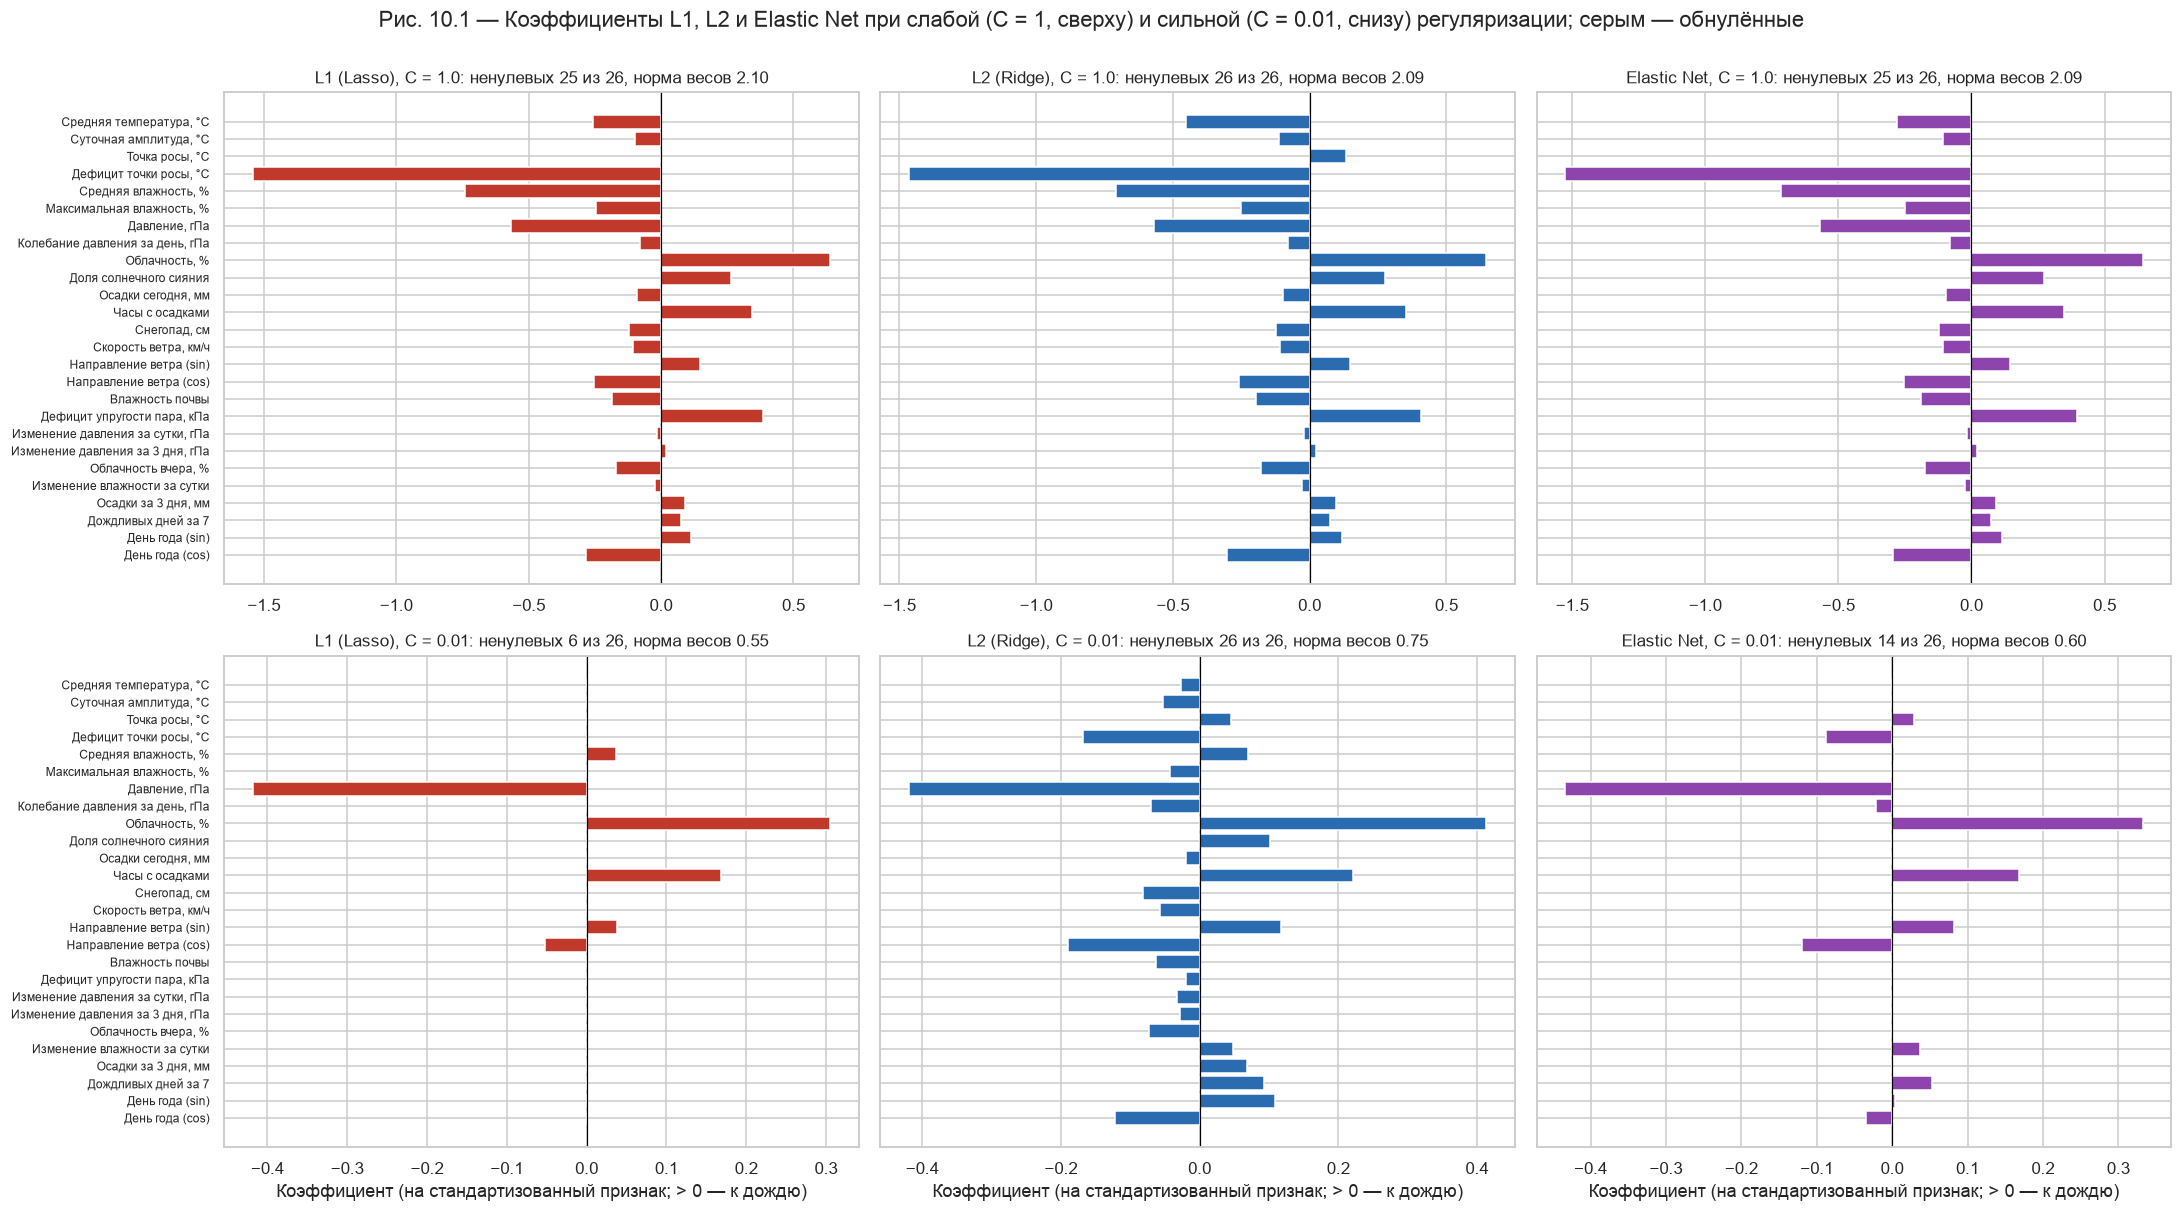

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(20, 11), sharey=True)
for row, C in enumerate([1.0, 0.01]):
    for col, m_name in enumerate(METHODS):
        w = pd.Series(coefficients(models_I[(C, m_name)]), index=RU)
        ax = axes[row, col]
        ax.barh(RU, w, color=np.where(np.abs(w) > 1e-10, METHOD_COLORS[m_name], "#CCCCCC"))
        ax.axvline(0, color="black", lw=0.8)
        nz = int((np.abs(w) > 1e-10).sum())
        ax.set_title(f"{m_name}, C = {C}: ненулевых {nz} из 26, норма весов {np.linalg.norm(w):.2f}", fontsize=11)
        ax.tick_params(axis="y", labelsize=8)
axes[0, 0].invert_yaxis()
for ax in axes[1]:
    ax.set_xlabel("Коэффициент (на стандартизованный признак; > 0 — к дождю)")
fig.suptitle("Рис. 10.1 — Коэффициенты L1, L2 и Elastic Net при слабой (C = 1, сверху) и сильной (C = 0.01, снизу) регуляризации; серым — обнулённые", y=1.0)
plt.tight_layout(); save("fig_10_1_coefficients_trio")

**Интерпретация (часть I, рис. 10.1).**

- **При C = 1 три «актёра» играют одинаково:** 25–26 ненулевых коэффициентов, ROC-AUC 0.762–0.763, F1 ≈ 0.51. На 2 916 днях обучения штраф при C = 1 почти не действует — различие методов проявляется только при сильной регуляризации. Это важно: в скриптах лекции везде C = 1, и на наших данных они показали бы «разницу без разницы».
- **Симптом при слабом штрафе — большие коэффициенты разных знаков у связанных признаков:** дефицит точки росы ≈ −1.5, средняя влажность ≈ −0.7 при положительной облачности. Дефицит точки росы — это ровно «температура − точка росы» (корреляция 1.0), поэтому веса этих признаков частично гасят друг друга. В части III.3 видно, чем это опасно при шуме датчиков.
- **При C = 0.01 «актёры» расходятся:**
  - **L1 оставляет 6 признаков из 26:** давление (−0.42), облачность (+0.31), часы с осадками (+0.17), обе компоненты направления ветра и среднюю влажность. ROC-AUC 0.795 — на уровне Random Forest (0.793) при 6 признаках вместо 26.
  - **L2 сохраняет все 26, но «приглушает»** (норма весов 0.75 против 2.09 при C = 1); ROC-AUC 0.784.
  - **Elastic Net — 14 признаков, ROC-AUC 0.796.**
  - F1 при пороге 0.5 — 0.54–0.55 (у Random Forest 0.519 при его пороге 0.23). Но PR-AUC линейных моделей ниже (0.50–0.51 против 0.551): Random Forest лучше ранжирует самые уверенные прогнозы.
- **Латентность.** Прогноз одной записи линейной моделью занимает 0.29 мс, Random Forest — 7.2 мс (в 25 раз дольше). Обучение линейной модели при C = 0.01 — 9–20 мс, Random Forest — ≈ 2.1 с (в 100–200 раз дольше).
- **Неожиданность относительно лекции** («L1 быстрый, L2 медленный»). При C = 1 L1 обучается **медленнее** L2 (≈ 220 против ≈ 115 мс), при C = 0.01 — быстрее всех (≈ 9 мс). Скорость решателя `saga` определяется прежде всего **силой** штрафа (при сильном штрафе он быстрее сходится), а не его типом.

**Почему именно такие роли (рефлексия части I):**
- **L1 — «скульптор-минималист»**, потому что штраф |w| стоит одинаково на любом расстоянии от нуля. Маленький, но полезный вес выгоднее занулить совсем, и признак «отсекается». Остаётся одно ядро — давление, облачность, осадки, ветер.
- **L2 — «художник-педант»**, потому что штраф w² возле нуля почти бесплатный. Веса уменьшаются, но не исчезают: каждый из 26 признаков сохраняет свой «мазок».
- **Elastic Net — «режиссёр»:** он отбирает признаки, как L1, но **группами**. Например, оставляет обе компоненты ветра и связанные признаки влажности, а L1 из группы связанных признаков выбирает один (произвольно, см. III.2).

---
# II. Адаптивность: как C и α меняют поведение «актёров»

Как в `elastic_net_adaptiv_trio.py`: перебираем **C** по логарифмической сетке (10⁻³ … 10) для трёх методов и **α** от 0 (чистый L2) до 1 (чистый L1) при фиксированном C. Смотрим качество (ROC-AUC на валидации 2023 и на тесте), число ненулевых коэффициентов и время обучения.

**Важно для честной оценки:** параметры выбираем **по валидации 2023**, тест 2024–2025 используется только для отчёта — как и при выборе Random Forest в ноутбуке 02.

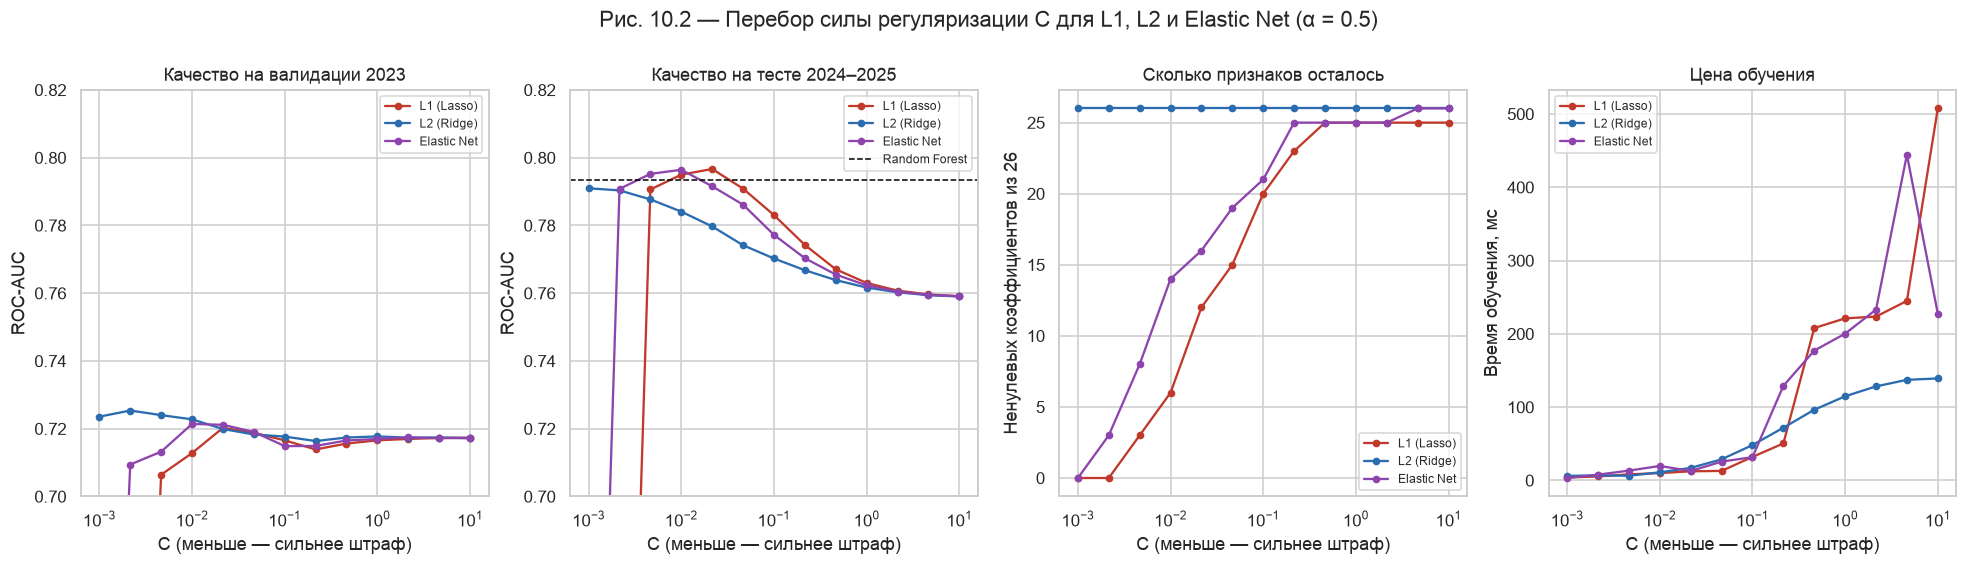

In [4]:
Cs = np.logspace(-3, 1, 13)
sweep = []
coef_paths = {m: [] for m in METHODS}
for C in Cs:
    for m_name, r in METHODS.items():
        m, fit_ms = fit_timed(make_model(C, r), X_tr, y_tr)
        pv, pt = m.predict_proba(X_va)[:, 1], m.predict_proba(X_te)[:, 1]
        w = coefficients(m); coef_paths[m_name].append(w)
        sweep.append({"C": C, "Метод": m_name, "ROC-AUC валидация": roc_auc_score(y_va, pv), "ROC-AUC тест": roc_auc_score(y_te, pt),
                      "F1 тест (0.5)": f1_score(y_te, pt >= 0.5), "Ненулевых": int((np.abs(w) > 1e-10).sum()), "Обучение, мс": fit_ms})
sweep = pd.DataFrame(sweep)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for m_name in METHODS:
    s = sweep[sweep["Метод"] == m_name]
    kw = dict(color=METHOD_COLORS[m_name], marker="o", ms=4)
    axes[0].plot(s.C, s["ROC-AUC валидация"], label=m_name, **kw)
    axes[1].plot(s.C, s["ROC-AUC тест"], label=m_name, **kw)
    axes[2].plot(s.C, s["Ненулевых"], label=m_name, **kw)
    axes[3].plot(s.C, s["Обучение, мс"], label=m_name, **kw)
axes[1].axhline(roc_auc_score(y_te, p_rf), color="black", ls="--", lw=1, label="Random Forest")
for ax, t, yl in zip(axes, ["Качество на валидации 2023", "Качество на тесте 2024–2025", "Сколько признаков осталось", "Цена обучения"],
                     ["ROC-AUC", "ROC-AUC", "Ненулевых коэффициентов из 26", "Время обучения, мс"]):
    ax.set_xscale("log"); ax.set(xlabel="C (меньше — сильнее штраф)", ylabel=yl, title=t); ax.legend(fontsize=8)
axes[0].set_ylim(0.7, 0.82); axes[1].set_ylim(0.7, 0.82)
fig.suptitle("Рис. 10.2 — Перебор силы регуляризации C для L1, L2 и Elastic Net (α = 0.5)", y=1.03)
save("fig_10_2_c_sweep")

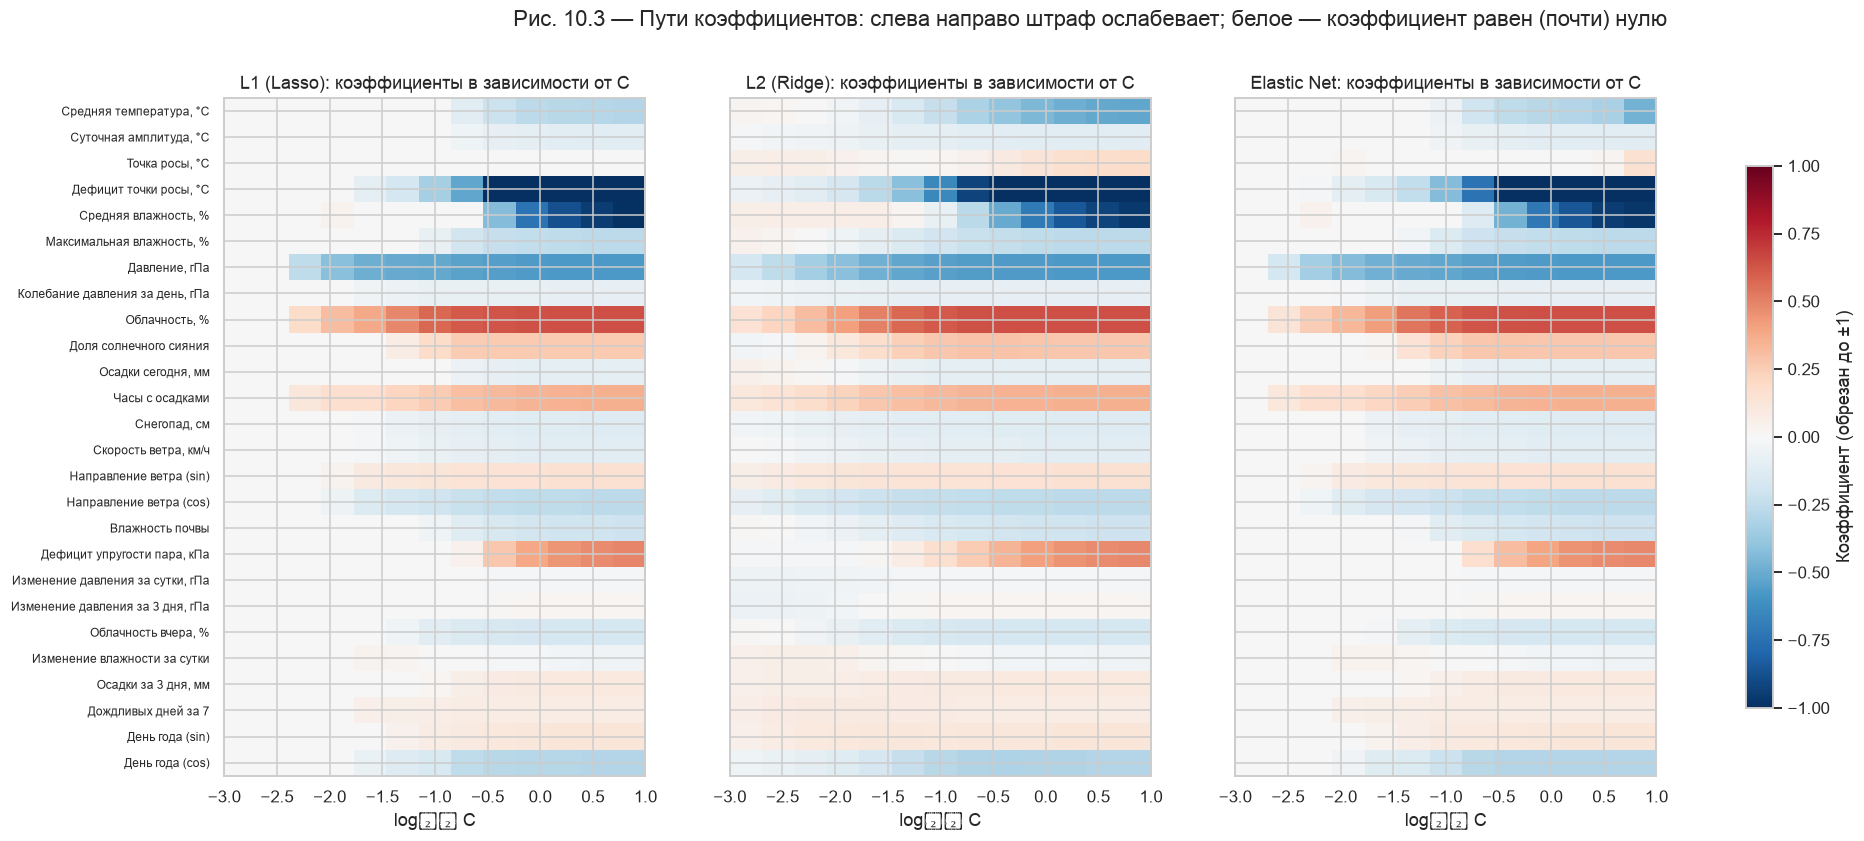

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(21, 8), sharey=True)
vmax = max(np.abs(np.array(v)).max() for v in coef_paths.values())
vmax = min(vmax, 1.0)
for ax, m_name in zip(axes, METHODS):
    M = np.array(coef_paths[m_name]).T
    im = ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=[np.log10(Cs[0]), np.log10(Cs[-1]), len(FEATURES) - 0.5, -0.5])
    ax.set_yticks(range(len(FEATURES))); ax.set_yticklabels(RU, fontsize=8)
    ax.set(xlabel="log₁₀ C", title=f"{m_name}: коэффициенты в зависимости от C")
fig.colorbar(im, ax=axes, shrink=0.8, label="Коэффициент (обрезан до ±1)")
fig.suptitle("Рис. 10.3 — Пути коэффициентов: слева направо штраф ослабевает; белое — коэффициент равен (почти) нулю", y=0.98)
save("fig_10_3_coef_paths")

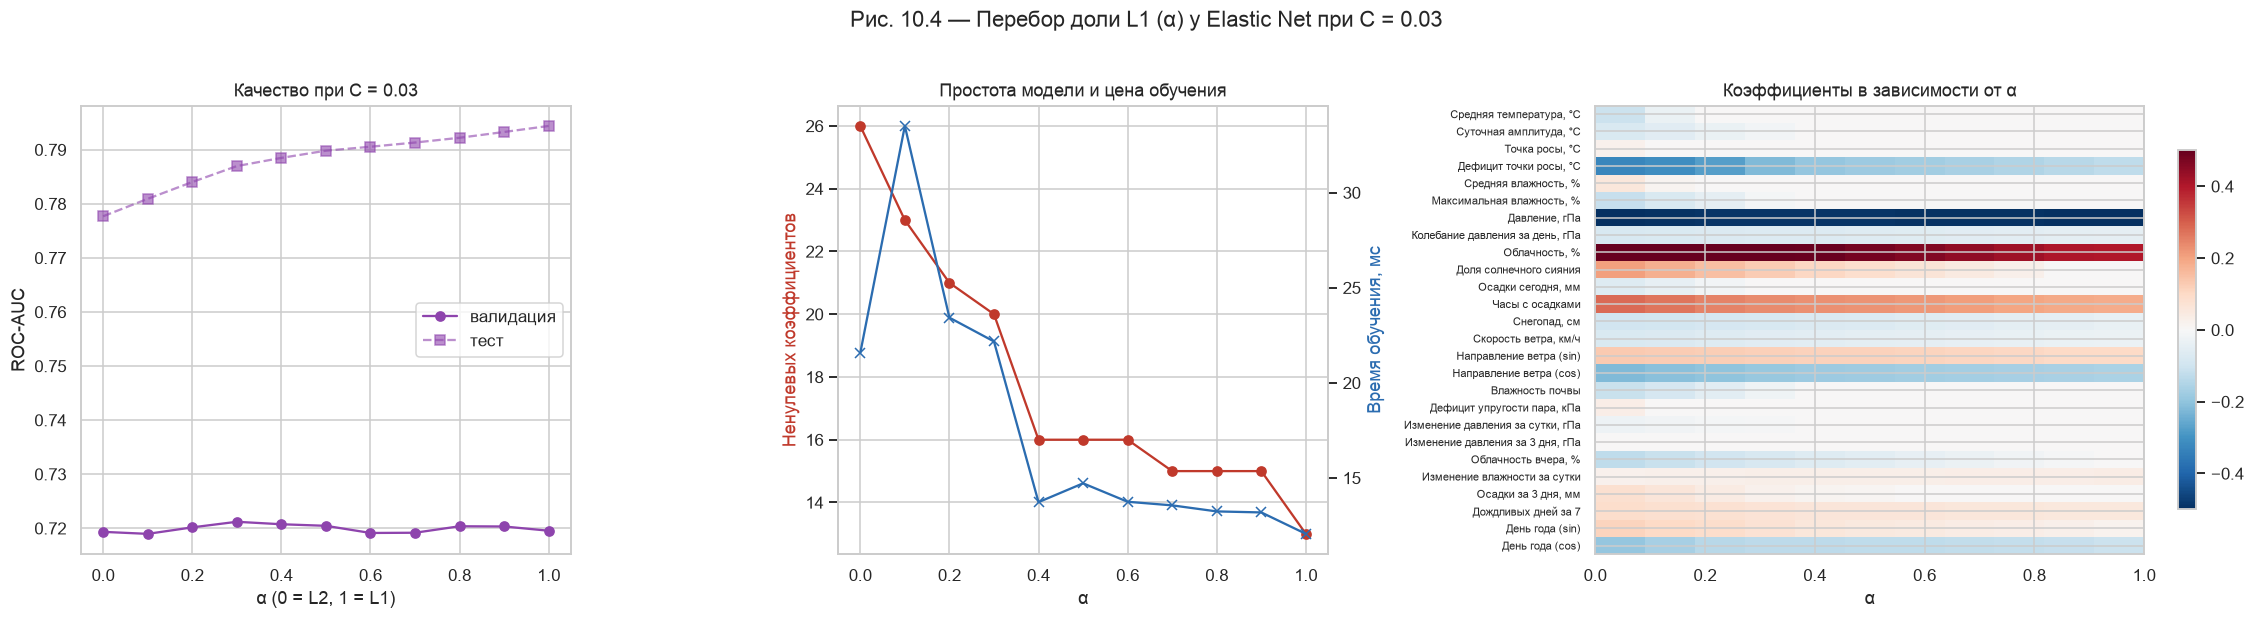

,α,ROC-AUC валидация,ROC-AUC тест,F1 тест (0.5),Ненулевых,"Обучение, мс"
0,0.0,0.719,0.778,0.531,26,21.575
1,0.1,0.719,0.781,0.540,23,33.507
2,0.2,0.720,0.784,0.543,21,23.429
3,0.3,0.721,0.787,0.548,20,22.177
4,0.4,0.721,0.788,0.548,16,13.728
5,0.5,0.720,0.790,0.549,16,14.718
6,0.6,0.719,0.791,0.550,16,13.749
7,0.7,0.719,0.791,0.546,15,13.559
8,0.8,0.720,0.792,0.548,15,13.241
9,0.9,0.720,0.793,0.548,15,13.188


In [6]:
C_FIX = 0.03
alphas = np.round(np.linspace(0, 1, 11), 2)
asweep, a_paths = [], []
for a in alphas:
    m, fit_ms = fit_timed(make_model(C_FIX, a), X_tr, y_tr)
    pv, pt = m.predict_proba(X_va)[:, 1], m.predict_proba(X_te)[:, 1]
    w = coefficients(m); a_paths.append(w)
    asweep.append({"α": a, "ROC-AUC валидация": roc_auc_score(y_va, pv), "ROC-AUC тест": roc_auc_score(y_te, pt),
                   "F1 тест (0.5)": f1_score(y_te, pt >= 0.5), "Ненулевых": int((np.abs(w) > 1e-10).sum()), "Обучение, мс": fit_ms})
asweep = pd.DataFrame(asweep)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
axes[0].plot(asweep["α"], asweep["ROC-AUC валидация"], "o-", color="#8E44AD", label="валидация")
axes[0].plot(asweep["α"], asweep["ROC-AUC тест"], "s--", color="#8E44AD", alpha=0.6, label="тест")
axes[0].set(xlabel="α (0 = L2, 1 = L1)", ylabel="ROC-AUC", title=f"Качество при C = {C_FIX}"); axes[0].legend()
ax2 = axes[1].twinx()
axes[1].plot(asweep["α"], asweep["Ненулевых"], "o-", color="#C0392B"); axes[1].set_ylabel("Ненулевых коэффициентов", color="#C0392B")
ax2.plot(asweep["α"], asweep["Обучение, мс"], "x-", color="#2B6CB0"); ax2.set_ylabel("Время обучения, мс", color="#2B6CB0"); ax2.grid(False)
axes[1].set(xlabel="α", title="Простота модели и цена обучения")
A = np.array(a_paths).T
im = axes[2].imshow(A, aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5, extent=[0, 1, len(FEATURES) - 0.5, -0.5])
axes[2].set_yticks(range(len(FEATURES))); axes[2].set_yticklabels(RU, fontsize=7)
axes[2].set(xlabel="α", title="Коэффициенты в зависимости от α"); fig.colorbar(im, ax=axes[2], shrink=0.8)
fig.suptitle(f"Рис. 10.4 — Перебор доли L1 (α) у Elastic Net при C = {C_FIX}", y=1.02)
plt.tight_layout(); save("fig_10_4_alpha_sweep")
asweep.round(3)

In [7]:
# selection on validation 2023: for each method the C (and α for ENet) with the best PR-AUC, then the F1 threshold
cands = []
for C in Cs:
    for a in [0.0, 0.25, 0.5, 0.75, 1.0]:
        m = make_model(C, a).fit(X_tr, y_tr)
        cands.append({"C": C, "α": a, "PR-AUC валидация": average_precision_score(y_va, m.predict_proba(X_va)[:, 1])})
cands = pd.DataFrame(cands)
BEST = {}
for m_name, sel in [("L1 (Lasso)", cands["α"] == 1.0), ("L2 (Ridge)", cands["α"] == 0.0), ("Elastic Net", (cands["α"] > 0) & (cands["α"] < 1))]:
    b = cands[sel].sort_values("PR-AUC валидация", ascending=False).iloc[0]
    m = make_model(b.C, b["α"]).fit(X_tr, y_tr)
    thr = best_threshold(y_va, m.predict_proba(X_va)[:, 1])
    BEST[m_name] = {"C": float(b.C), "α": float(b["α"]), "thr": thr, "model": m}
rows = []
for m_name, b in BEST.items():
    p = b["model"].predict_proba(X_te)[:, 1]
    rows.append({"Метод": m_name, "C": round(b["C"], 4), "α": b["α"], "Порог (валидация)": b["thr"], "ROC-AUC": roc_auc_score(y_te, p),
                 "PR-AUC": average_precision_score(y_te, p), "F1": f1_score(y_te, p >= b["thr"]), "Recall": recall_score(y_te, p >= b["thr"]),
                 "Precision": precision_score(y_te, p >= b["thr"]), "Ненулевых": int((np.abs(coefficients(b["model"])) > 1e-10).sum())})
rows.append({"Метод": "Random Forest", "C": "—", "α": "—", "Порог (валидация)": THR_RF, "ROC-AUC": roc_auc_score(y_te, p_rf),
             "PR-AUC": average_precision_score(y_te, p_rf), "F1": f1_score(y_te, p_rf >= THR_RF), "Recall": recall_score(y_te, p_rf >= THR_RF),
             "Precision": precision_score(y_te, p_rf >= THR_RF), "Ненулевых": "—"})
best_tbl = pd.DataFrame(rows)
print("Выбор по PR-AUC на валидации 2023; метрики — на тесте 2024–2025")
best_tbl.round(3)

Выбор по PR-AUC на валидации 2023; метрики — на тесте 2024–2025


,Метод,C,α,Порог (валидация),ROC-AUC,PR-AUC,F1,Recall,Precision,Ненулевых
0,L1 (Lasso),0.0464,1.0,0.49,0.791,0.510,0.537,0.758,0.416,15
1,L2 (Ridge),0.001,0.0,0.43,0.791,0.506,0.494,0.832,0.352,26
2,Elastic Net,0.01,0.25,0.49,0.793,0.510,0.541,0.758,0.421,17
3,Random Forest,—,—,0.23,0.793,0.551,0.519,0.758,0.395,—


**Интерпретация (часть II, рис. 10.2–10.4).**

- **Сила штрафа важнее его типа (рис. 10.2).** При уменьшении C от 10 до ≈ 0.01 ROC-AUC на тесте растёт с 0.759 до 0.795–0.797 у L1 и ENet; L2 достигает 0.791 при C = 0.001.
- **Перебор силы штрафа тоже вреден.** При C = 0.001 L1 и ENet обнуляют **все** коэффициенты, и модель вырождается в константу (ROC-AUC 0.5).
- **Отбор признаков (рис. 10.3).** Первыми «выживают» давление и облачность (при C ≈ 0.005 у L1 их 3), затем часы с осадками и ветер. Последними включаются связанные признаки влажности и температуры: именно они при слабом штрафе получают большие веса разных знаков.
- **α (рис. 10.4)** плавно переводит ENet от L2 к L1: при C = 0.03 число признаков падает с 26 до 13, ROC-AUC на тесте растёт с 0.778 до 0.794. На валидации α почти ни на что не влияет (0.719–0.721).
- **Честная оговорка о выборе по валидации.** 2023 год (валидация) почти не различает модели: ROC-AUC 0.717–0.721 при любом C и α, а на тесте 2024–2025 сильный штраф даёт +0.035. Выбор по PR-AUC на валидации дал L1: C = 0.046 (15 признаков), L2: C = 0.001, ENet: C = 0.01, α = 0.25 (17 признаков).
  - Тест: ROC-AUC 0.791 / 0.791 / 0.793 (Random Forest 0.793), F1 0.537 / 0.494 / 0.541 (Random Forest 0.519), PR-AUC 0.51 (Random Forest 0.551).
  - Выигрыш сильного штрафа на тесте объясняется **сдвигом данных:** 2024–2025 отличаются от лет обучения (засуха, ноутбук 08). Простая модель переносит это лучше — та же причина, по которой она устойчивее к шуму (III.3).

**Таблица лекции «C мал / C велик / α мал / α велик» (наши данные):**

| Метод | C мал (сильный штраф, C ≈ 0.005–0.05) | C велик (слабый штраф, C ≥ 1) | α мал | α велик |
|---|---|---|---|---|
| **L1** | 3–15 признаков (давление, облачность, часы с осадками, ветер); ROC-AUC до 0.797; обучение 7–13 мс; при C ≤ 0.002 — все веса 0 | 25 признаков; ROC-AUC 0.76; обучение 220–520 мс | — | — |
| **L2** | все 26, веса малы; ROC-AUC до 0.791 (при C = 0.001); 6–30 мс | все 26, большие веса разных знаков у связанных признаков; ROC-AUC 0.76; 120–140 мс | — | — |
| **ENet** | 8–19 признаков, группы связанных признаков; ROC-AUC до 0.796 | как L2 и L1 (25–26 признаков, 0.76) | ≈ L2: все 26 признаков | ≈ L1: 13 признаков, быстрее (12 мс против 22) |

---
# III. Стриминг: «актёры» на сцене потока 2024–2025

Как в `elastic_net_streaming_trio.py`, но вместо случайных пакетов из синтетических данных — **реальный поток**: в начале каждого месяца 2024–2025 модель переобучается на всей накопленной истории (микропакет), а затем прогнозирует дни этого месяца по одному. Так коэффициенты действительно «движутся во времени» (24 переобучения), а качество меряется на днях, которых модель не видела.

Параметры каждого метода — выбранные по валидации (часть II); для сравнения добавлены L2 с C = 1 (значение по умолчанию) и Random Forest с тем же ежемесячным переобучением.

In [8]:
streams = {}
for m_name, b in BEST.items():
    streams[m_name] = stream_retrain(raw, lambda ni, b=b: (b["C"], b["α"]), data=data) + (b["thr"],)
p_va_l2 = make_model(1.0, 0.0).fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
streams["L2, C = 1 (по умолчанию)"] = stream_retrain(raw, lambda ni: (1.0, 0.0), data=data) + (best_threshold(y_va, p_va_l2),)

# Random Forest with the same monthly retraining (reference)
rf_preds, rf_fit = [], []
for per in pd.period_range("2024-01", "2025-12", freq="M"):
    hist = data[data.date < per.start_time]; cur = data[(data.date >= per.start_time) & (data.date <= per.end_time)]
    m, ms = fit_timed(clone(rf).set_params(n_jobs=1), hist[FEATURES], hist[TARGET])
    rf_fit.append(ms); rf_preds.append(pd.DataFrame({"date": cur.date.to_numpy(), "y": cur[TARGET].to_numpy(), "p": m.predict_proba(cur[FEATURES])[:, 1]}))
rf_stream = pd.concat(rf_preds, ignore_index=True)

rows = []
for s_name, (P, LOG, thr) in streams.items():
    last = make_model(LOG.C.iloc[-1], LOG.l1_ratio.iloc[-1]).fit(X_tr, y_tr)
    rows.append({"Модель в потоке": s_name, "ROC-AUC": roc_auc_score(P.y, P.p), "F1": f1_score(P.y, P.p >= thr), "Recall": recall_score(P.y, P.p >= thr),
                 "24 переобучения, с": LOG.fit_ms.sum() / 1000, "Прогноз 1 записи, мс": predict_latency_ms(last, X_te),
                 "Ненулевых (медиана)": int(LOG.nonzero.median())})
rows.append({"Модель в потоке": "Random Forest", "ROC-AUC": roc_auc_score(rf_stream.y, rf_stream.p), "F1": f1_score(rf_stream.y, rf_stream.p >= THR_RF),
             "Recall": recall_score(rf_stream.y, rf_stream.p >= THR_RF), "24 переобучения, с": sum(rf_fit) / 1000,
             "Прогноз 1 записи, мс": predict_latency_ms(rf1, X_te, n=100), "Ненулевых (медиана)": "—"})
stream_tbl = pd.DataFrame(rows)
stream_tbl.round(3)

,Модель в потоке,ROC-AUC,F1,Recall,"24 переобучения, с","Прогноз 1 записи, мс",Ненулевых (медиана)
0,L1 (Lasso),0.790,0.541,0.745,0.381,0.293,17
1,L2 (Ridge),0.791,0.503,0.820,0.175,0.295,26
2,Elastic Net,0.792,0.539,0.745,0.517,0.291,18
3,"L2, C = 1 (по умолчанию)",0.772,0.516,0.733,3.387,0.290,26
4,Random Forest,0.796,0.524,0.758,65.846,7.222,—


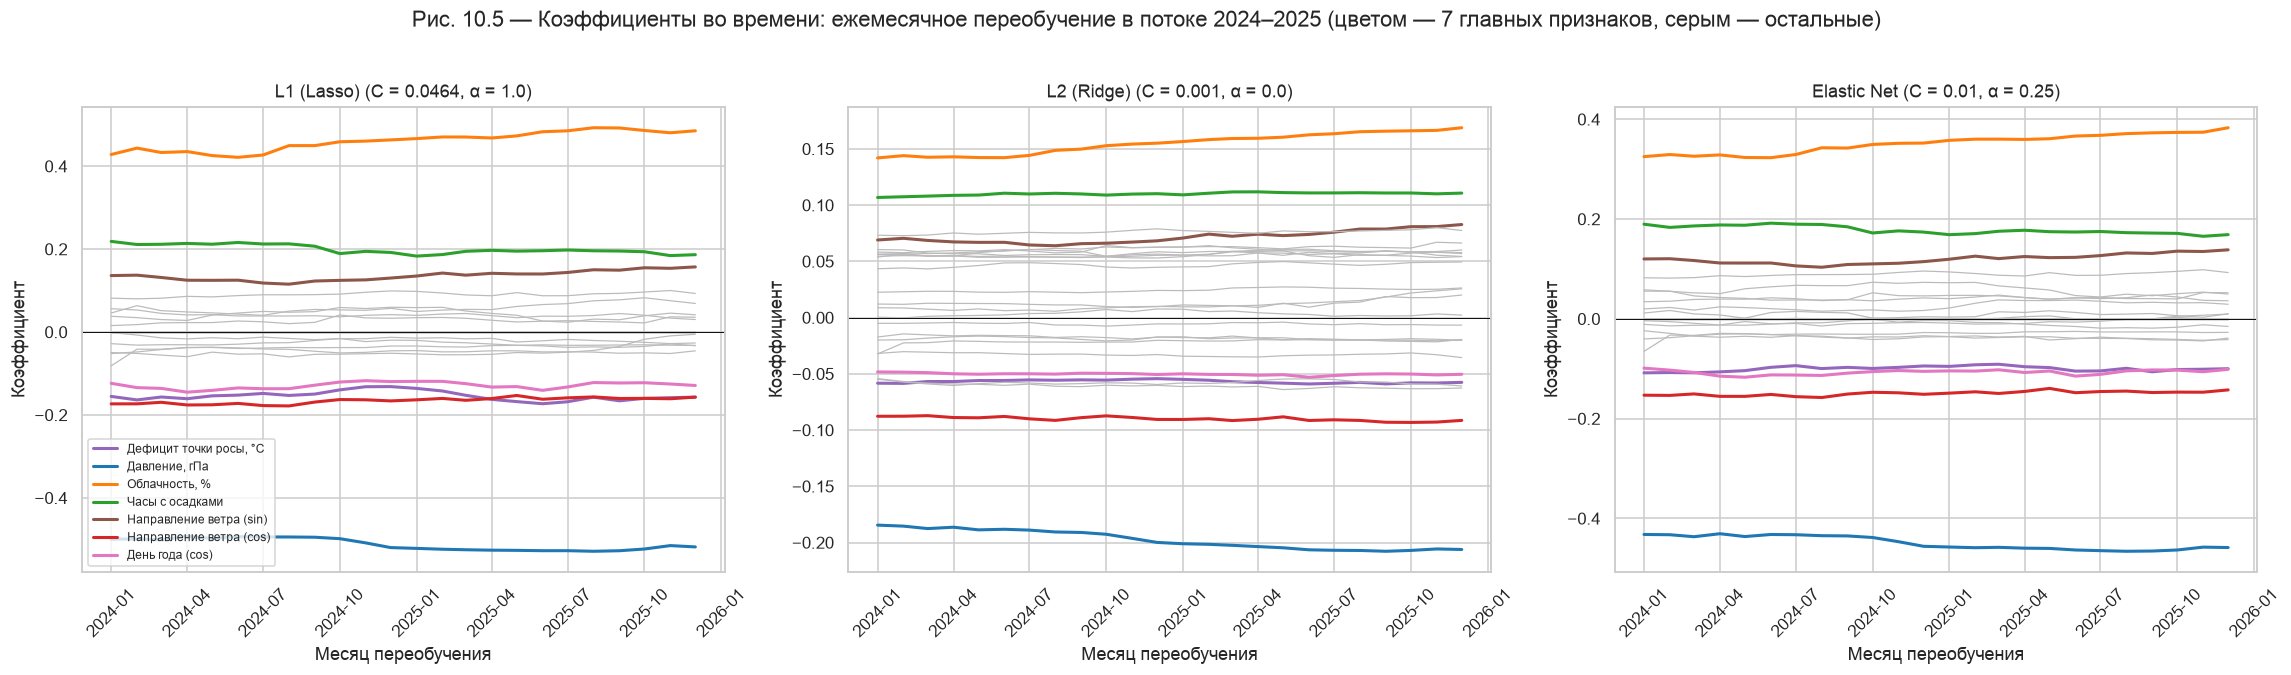

,Метод,Среднее |Δw| за месяц,Относит. изменение ‖Δw‖/‖w‖,Включений/выключений признаков,Ненулевых (мин–макс)
0,L1 (Lasso),0.0025,0.0269,0,17–17
1,L2 (Ridge),0.0010,0.0182,0,26–26
2,Elastic Net,0.0021,0.0251,14,17–19


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharey=False)
LOGS = {m: streams[m][1] for m in METHODS}
top = pd.concat([LOGS[m][FEATURES].abs().mean() for m in METHODS], axis=1).max(axis=1).sort_values(ascending=False).index[:7]
palette = dict(zip(top, sns.color_palette("tab10", len(top))))
stab_rows = []
for ax, m_name in zip(axes, METHODS):
    LOG = LOGS[m_name]
    for f in FEATURES:
        if f in top:
            ax.plot(LOG.period, LOG[f], color=palette[f], lw=2, label=FEATURE_NAMES_RU[f])
        else:
            ax.plot(LOG.period, LOG[f], color="#BBBBBB", lw=0.8)
    ax.axhline(0, color="black", lw=0.6)
    b = BEST[m_name]
    ax.set(title=f"{m_name} (C = {b['C']:.3g}, α = {b['α']})", xlabel="Месяц переобучения", ylabel="Коэффициент")
    ax.tick_params(axis="x", rotation=45)
    W = LOG[FEATURES].to_numpy()
    on = np.abs(W) > 1e-10
    stab_rows.append({"Метод": m_name, "Среднее |Δw| за месяц": np.abs(np.diff(W, axis=0)).mean(),
                      "Относит. изменение ‖Δw‖/‖w‖": (np.linalg.norm(np.diff(W, axis=0), axis=1) / np.linalg.norm(W[1:], axis=1)).mean(),
                      "Включений/выключений признаков": int(np.abs(np.diff(on.astype(int), axis=0)).sum()),
                      "Ненулевых (мин–макс)": f"{on.sum(1).min()}–{on.sum(1).max()}"})
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Рис. 10.5 — Коэффициенты во времени: ежемесячное переобучение в потоке 2024–2025 (цветом — 7 главных признаков, серым — остальные)", y=1.02)
plt.tight_layout(); save("fig_10_5_coefficients_in_stream")
pd.DataFrame(stab_rows).round(4)

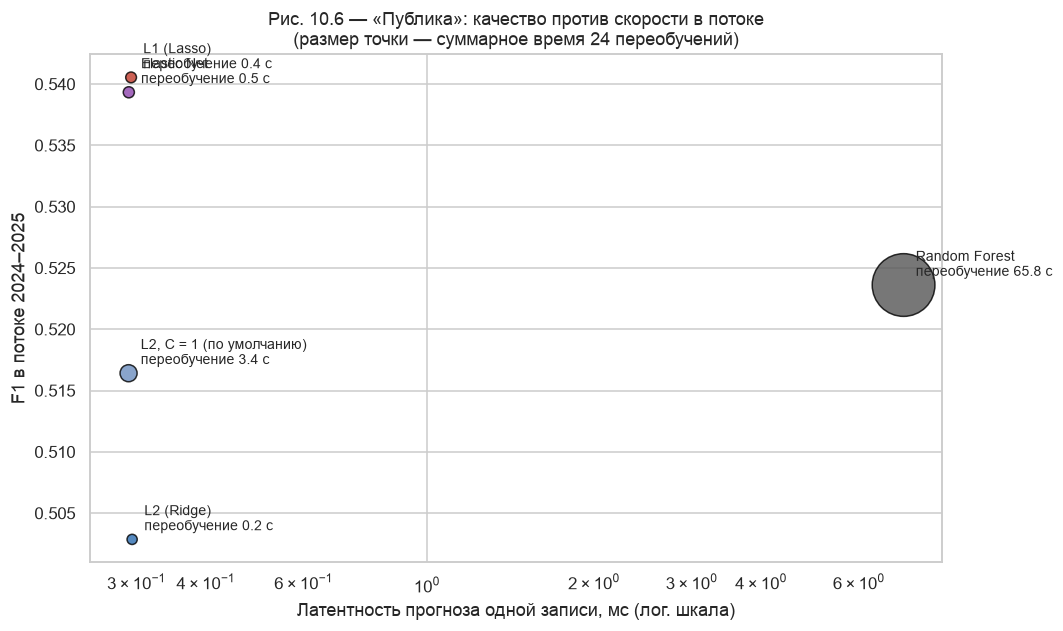

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
pts = stream_tbl.copy()
colors = [METHOD_COLORS.get(n, "#555555" if "Random" in n else "#6C8EBF") for n in pts["Модель в потоке"]]
ax.scatter(pts["Прогноз 1 записи, мс"], pts["F1"], s=40 + 25 * pts["24 переобучения, с"], c=colors, alpha=0.8, edgecolor="black")
for _, r in pts.iterrows():
    ax.annotate(f"{r['Модель в потоке']}\nпереобучение {r['24 переобучения, с']:.1f} с", (r["Прогноз 1 записи, мс"], r["F1"]),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
ax.set_xscale("log")
ax.set(xlabel="Латентность прогноза одной записи, мс (лог. шкала)", ylabel="F1 в потоке 2024–2025",
       title="Рис. 10.6 — «Публика»: качество против скорости в потоке\n(размер точки — суммарное время 24 переобучений)")
save("fig_10_6_f1_vs_latency")

**Интерпретация (часть III, рис. 10.5–10.6).**

- **Коэффициенты в потоке меняются плавно, без скачков (рис. 10.5).** За месяц вектор весов меняется в среднем на 1.8 % (L2), 2.5 % (ENet) и 2.7 % (L1).
  - L1 в потоке **ни разу не включил и не выключил признак**: все 24 переобучения — те же 17 признаков.
  - У ENet было 14 включений/выключений (17–19 признаков) — слабые признаки «мерцают» у нуля.
  - За 2024–2025 растёт вес облачности (у L1: 0.43 → 0.49) и усиливается отрицательный вес давления (−0.49 → −0.52). Модель, дообучаясь на новых годах, всё больше опирается на облачность — это медленный дрейф зависимости, а не шум.
- **Качество в потоке ≈ качество статичной модели:** ROC-AUC 0.790 / 0.791 / 0.792 у L1 / L2 / ENet, у Random Forest 0.796 (тот же месячный ритм переобучения).
  - По F1 ENet и L1 (0.539–0.541) лучше Random Forest (0.524) и L2 (0.503 — его порог 0.43 с валидации неудачно перенёсся на поток).
  - L2 с C = 1 (как в лекции) — худший: ROC-AUC 0.772.
- **Цена потока (рис. 10.6).**
  - 24 переобучения: 0.2–0.5 с у L1 / L2 / ENet, 3.4 с у L2 с C = 1, 65 с у Random Forest — в 130 раз дольше ENet.
  - Прогноз одной записи — 0.3 мс против 7.3 мс.
  - Для нашей станции (одна запись в сутки) это не ограничение: даже Random Forest укладывается в миллисекунды. Но при масштабировании (тысячи станций, данные каждые 10 минут, еженедельное переобучение по всей сети) разница в 25–130 раз решает, хватит ли одного сервера.

## III.2 Устойчивость коэффициентов (variance): проверяем утверждение лекции

Лекция связывает регуляризацию с темами bias / variance: *«L2 стабилизирует коэффициенты… L1 уменьшает variance за счёт упрощения»*. Проверяем это напрямую: **30 бутстрэп-выборок** из обучения (как 30 разных «историй», на которых мог бы учиться поток), одна и та же сила штрафа C = 0.03 для всех трёх методов. Меряем:
- как часто признак попадает в модель (для L1 / ENet) — стабилен ли **отбор**;
- сколько признаков меняют **знак** коэффициента между выборками;
- относительный разброс коэффициентов (стандартное отклонение / средний модуль).

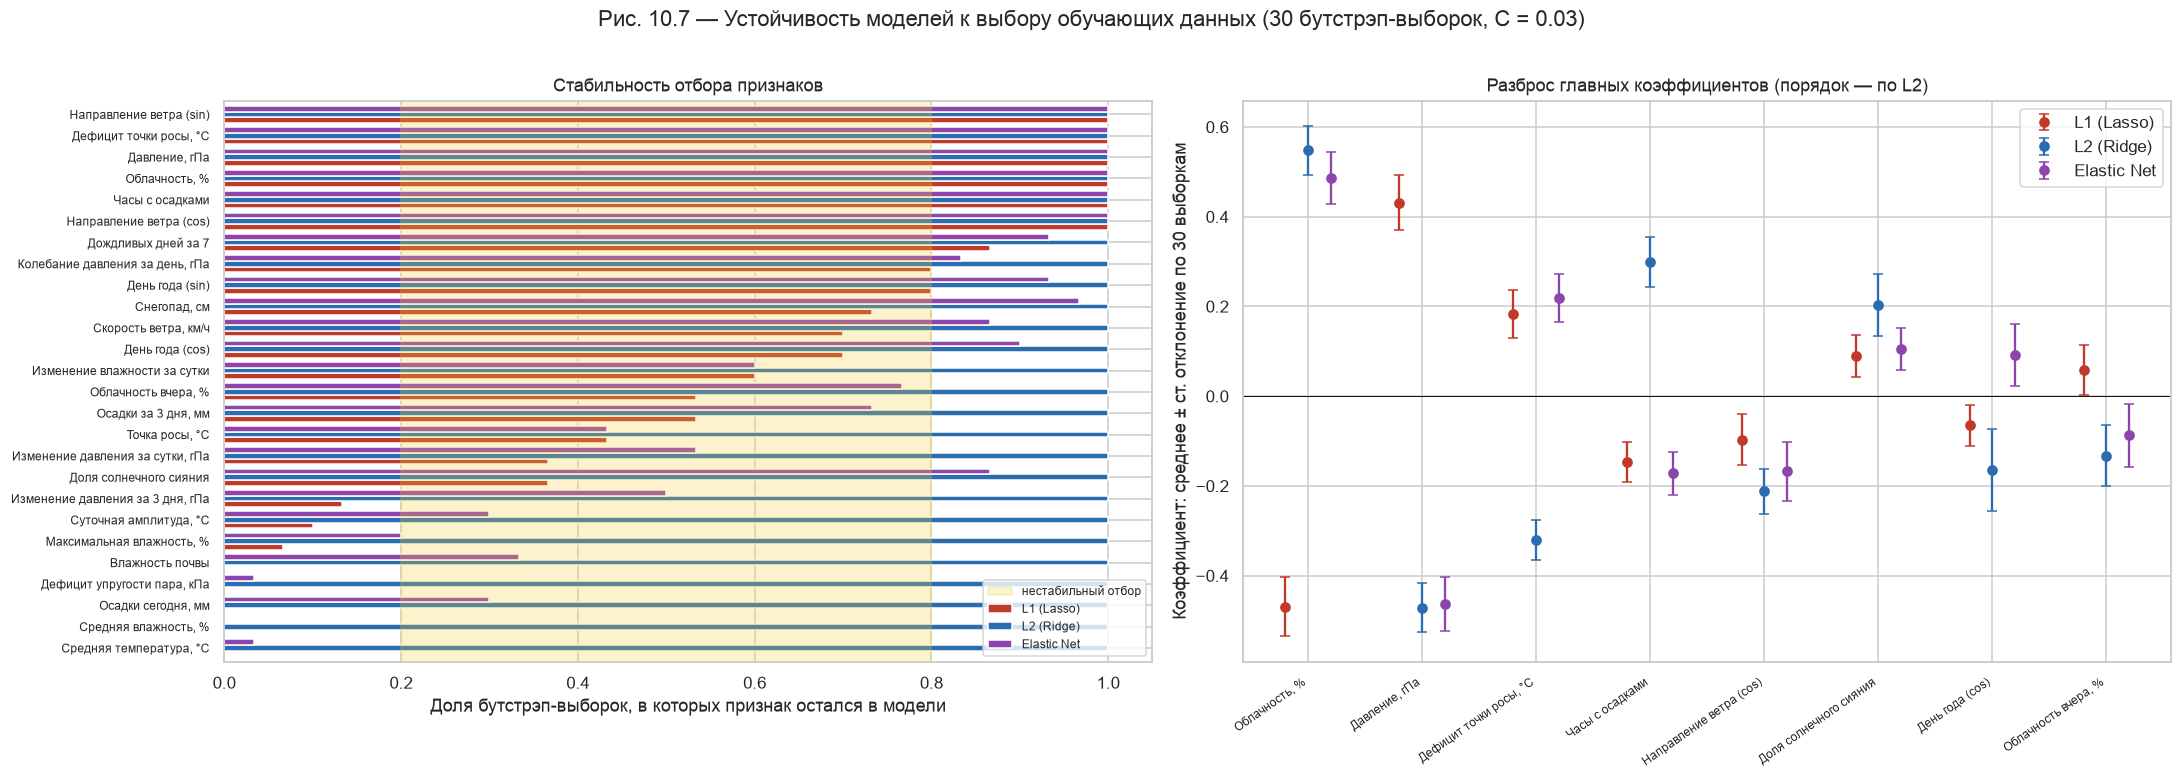

,Метод,Признаков в модели (медиана),Нестабильный отбор (входит в 20–80 % выборок),"Признаков, меняющих знак",Относит. разброс главных 8 коэф.
0,L1 (Lasso),14,9,2,0.416
1,L2 (Ridge),26,0,16,0.214
2,Elastic Net,17,9,6,0.334


In [11]:
rng = np.random.default_rng(SEED)
B, C_BOOT = 30, 0.03
boot = {m: [] for m in METHODS}
idx = [rng.choice(len(X_tr), len(X_tr), replace=True) for _ in range(B)]
for m_name, r in METHODS.items():
    for i in idx:
        boot[m_name].append(coefficients(make_model(C_BOOT, r).fit(X_tr.iloc[i], y_tr.iloc[i])))
rows, freq = [], {}
for m_name, W in boot.items():
    W = np.array(W); on = np.abs(W) > 1e-10
    freq[m_name] = on.mean(0)
    rows.append({"Метод": m_name, "Признаков в модели (медиана)": int(np.median(on.sum(1))),
                 "Нестабильный отбор (входит в 20–80 % выборок)": int(((on.mean(0) > 0.2) & (on.mean(0) < 0.8)).sum()),
                 "Признаков, меняющих знак": int(((W > 1e-10).any(0) & (W < -1e-10).any(0)).sum()),
                 "Относит. разброс главных 8 коэф.": float(np.median((W.std(0) / (np.abs(W.mean(0)) + 1e-12))[np.argsort(-np.abs(W.mean(0)))[:8]]))})
boot_tbl = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(20, 7))
F = pd.DataFrame(freq, index=RU)
F.sort_values("L1 (Lasso)").plot.barh(ax=axes[0], color=[METHOD_COLORS[m] for m in METHODS], width=0.8)
axes[0].axvspan(0.2, 0.8, color="#F5D33B", alpha=0.25, label="нестабильный отбор")
axes[0].set(xlabel="Доля бутстрэп-выборок, в которых признак остался в модели", title="Стабильность отбора признаков"); axes[0].legend(fontsize=8)
axes[0].tick_params(axis="y", labelsize=8)
for m_name in METHODS:
    W = np.array(boot[m_name]); order = np.argsort(-np.abs(W.mean(0)))[:8]
    axes[1].errorbar(np.arange(8) + {"L1 (Lasso)": -0.2, "L2 (Ridge)": 0, "Elastic Net": 0.2}[m_name], W.mean(0)[order], yerr=W.std(0)[order],
                     fmt="o", color=METHOD_COLORS[m_name], capsize=3, label=m_name)
    if m_name == "L2 (Ridge)":
        axes[1].set_xticks(range(8)); axes[1].set_xticklabels([RU[j] for j in order], rotation=35, ha="right", fontsize=8)
axes[1].axhline(0, color="black", lw=0.6)
axes[1].set(ylabel="Коэффициент: среднее ± ст. отклонение по 30 выборкам", title="Разброс главных коэффициентов (порядок — по L2)"); axes[1].legend()
fig.suptitle(f"Рис. 10.7 — Устойчивость моделей к выбору обучающих данных (30 бутстрэп-выборок, C = {C_BOOT})", y=1.01)
plt.tight_layout(); save("fig_10_7_bootstrap_stability")
boot_tbl.round(3)

**Интерпретация (рис. 10.7).**

- **Утверждение лекции «L2 стабилизирует коэффициенты» подтверждается.** Относительный разброс 8 главных весов по 30 выборкам: 0.21 у L2, 0.33 у ENet, 0.42 у L1.
- **Утверждение «L1 уменьшает разброс за счёт упрощения» — нет.** Модель L1 проще (14 признаков), но **отбор признаков нестабилен**: 9 признаков попадают в модель лишь в 20–80 % выборок. Из группы связанных признаков (влажность, точка росы, температура) L1 каждый раз выбирает «представителя» почти случайно. У L2 нестабильного отбора нет по определению, а 16 «смен знака» — это мелкие веса около нуля, которые для прогноза ничего не значат.
- **Почему в потоке (рис. 10.5) L1 был стабилен, а здесь — нет.** В потоке данные каждого месяца — это прежние данные плюс один месяц, почти та же выборка. Бутстрэп моделирует **другую историю** (другие годы, другая станция). Значит, список признаков L1 не стоит толковать как «физически главные признаки»: устойчиво только ядро — давление, облачность, часы с осадками, ветер.
- **Мера (снизить влияние):** для интерпретации — Elastic Net (группы признаков) или L2; для отбора признаков — выбирать признаки, которые попадают в модель в ≥ 80 % бутстрэп-выборок (стабильный отбор), а не по одной модели L1.

## III.3 Шум датчиков и «адаптивный режиссёр»: обнаружить → смоделировать → снизить

Лекция предлагает адаптивный Elastic Net: *«шум растёт → α сдвигается к L2 (сохранить детали); латентность растёт → α сдвигается к L1 (ускорить)»*. Проверяем это правило на нашей задаче.

**1. Смоделировать.** Гауссов шум с σ = k × (стандартное отклонение датчика в годы обучения) на **четыре датчика**: влажность, облачность, давление, точка росы — как при деградации метеостанции. Шум вносится в **исходные измерения**, и признаки пересчитываются (шум давления попадает и в «изменение давления»).

**2. Статичная модель** (обучена на чистых 2015–2022) на зашумлённом тесте: какие C и α устойчивее.

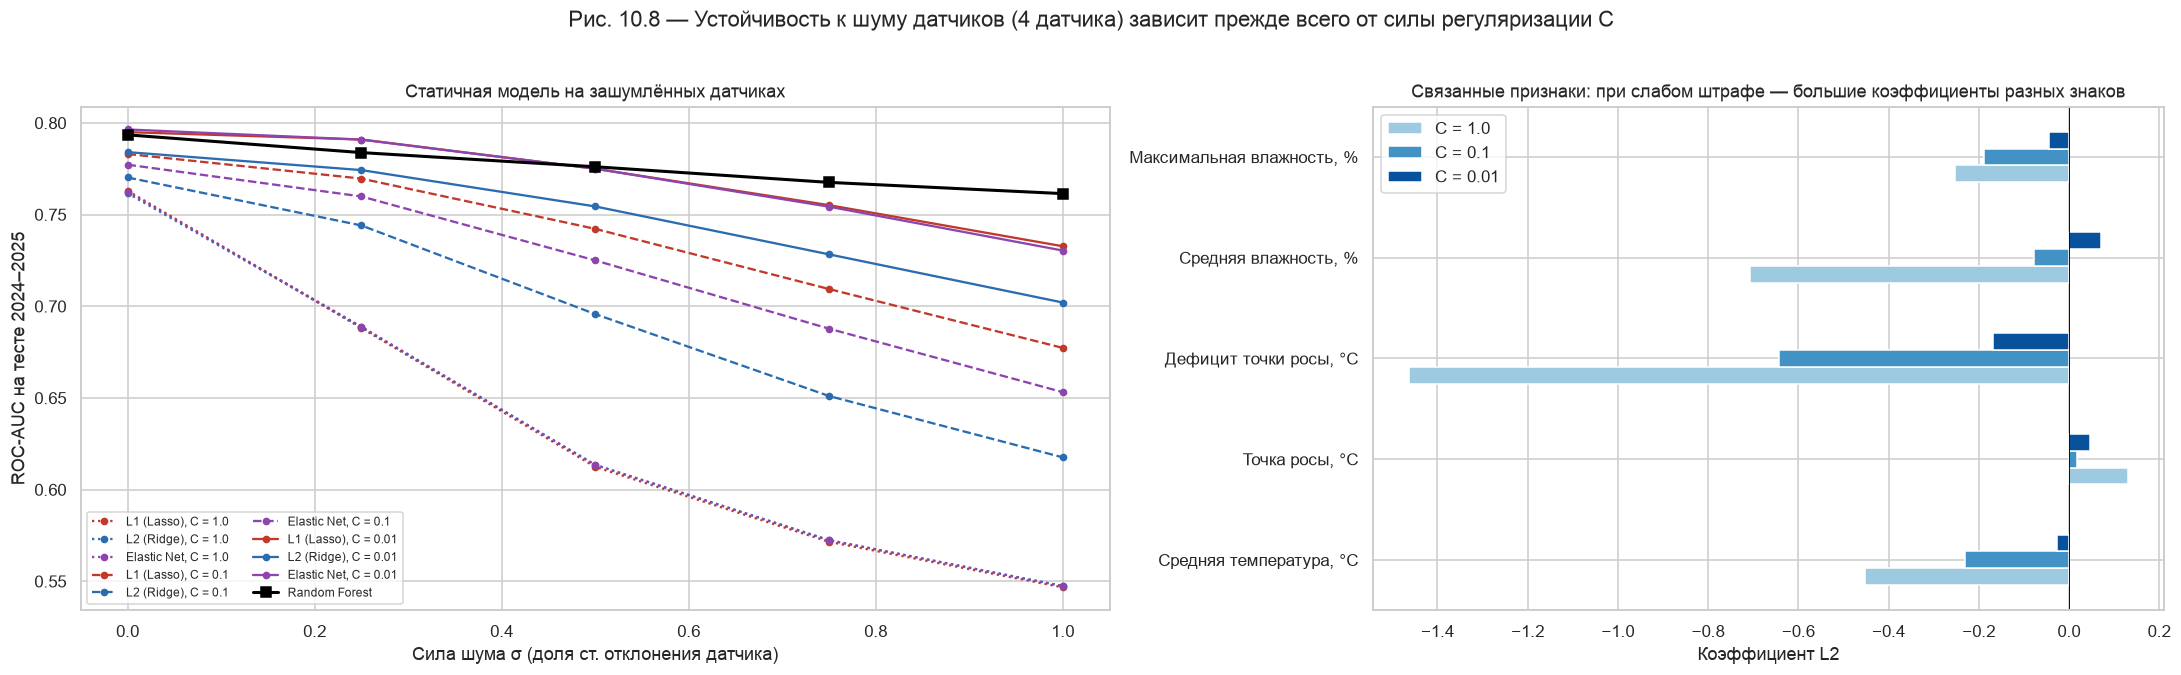

Проверка связи: дефицит точки росы = температура − точка росы (корреляция 1.0000), точка росы и температура: r = 0.93


σ                  0.00   0.25   0.50   0.75   1.00
C    Метод                                         
0.01 Elastic Net  0.796  0.791  0.775  0.754  0.730
     L1 (Lasso)   0.795  0.791  0.775  0.755  0.733
     L2 (Ridge)   0.784  0.774  0.754  0.728  0.702
0.10 Elastic Net  0.777  0.760  0.725  0.688  0.653
     L1 (Lasso)   0.783  0.770  0.742  0.709  0.677
     L2 (Ridge)   0.770  0.744  0.696  0.651  0.618
1.00 Elastic Net  0.762  0.689  0.614  0.573  0.547
     L1 (Lasso)   0.763  0.688  0.612  0.572  0.547
     L2 (Ridge)   0.762  0.689  0.614  0.572  0.548

In [12]:
static = {(C, m_name): make_model(C, r).fit(X_tr, y_tr) for C in [1.0, 0.1, 0.01] for m_name, r in METHODS.items()}
sigmas = [0, 0.25, 0.5, 0.75, 1.0]
rob = []
for s in sigmas:
    d = build_features(add_sensor_noise(raw, sigma=s, start="2024-01-01"))
    t = d[d.date.dt.year >= 2024]
    for (C, m_name), m in static.items():
        rob.append({"σ": s, "C": C, "Метод": m_name, "ROC-AUC": roc_auc_score(t[TARGET], m.predict_proba(t[FEATURES])[:, 1])})
rob = pd.DataFrame(rob)
p_rf_noisy = {s: roc_auc_score(*(lambda t: (t[TARGET], rf.predict_proba(t[FEATURES])[:, 1]))(
    (lambda d: d[d.date.dt.year >= 2024])(build_features(add_sensor_noise(raw, sigma=s, start="2024-01-01"))))) for s in sigmas}

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={"width_ratios": [1.3, 1]})
for C, ls in zip([1.0, 0.1, 0.01], [":", "--", "-"]):
    for m_name in METHODS:
        s = rob[(rob.C == C) & (rob["Метод"] == m_name)]
        axes[0].plot(s["σ"], s["ROC-AUC"], ls=ls, marker="o", ms=4, color=METHOD_COLORS[m_name], label=f"{m_name}, C = {C}")
axes[0].plot(sigmas, list(p_rf_noisy.values()), color="black", marker="s", lw=2, label="Random Forest")
axes[0].set(xlabel="Сила шума σ (доля ст. отклонения датчика)", ylabel="ROC-AUC на тесте 2024–2025",
            title="Статичная модель на зашумлённых датчиках"); axes[0].legend(fontsize=8, ncol=2)
# why weak regularization amplifies noise: collinear temperature / dew point / dew point depression
trio = ["temperature_2m_mean", "dew_point_2m_mean", "dew_point_depression", "relative_humidity_2m_mean", "relative_humidity_2m_max"]
cw = pd.DataFrame({f"C = {C}": coefficients(static[(C, "L2 (Ridge)")]) for C in [1.0, 0.1, 0.01]}, index=FEATURES).loc[trio]
cw.index = [FEATURE_NAMES_RU[f] for f in trio]
cw.plot.barh(ax=axes[1], color=["#9ECAE1", "#4292C6", "#08519C"])
axes[1].axvline(0, color="black", lw=0.6)
axes[1].set(xlabel="Коэффициент L2", title="Связанные признаки: при слабом штрафе — большие коэффициенты разных знаков")
fig.suptitle("Рис. 10.8 — Устойчивость к шуму датчиков (4 датчика) зависит прежде всего от силы регуляризации C", y=1.02)
plt.tight_layout(); save("fig_10_8_noise_robustness")
corr_dp = np.corrcoef(train.temperature_2m_mean - train.dew_point_2m_mean, train.dew_point_depression)[0, 1]
print(f"Проверка связи: дефицит точки росы = температура − точка росы (корреляция {corr_dp:.4f}), точка росы и температура: r = {train[['temperature_2m_mean','dew_point_2m_mean']].corr().iloc[0,1]:.2f}")
rob.pivot_table(index=["C", "Метод"], columns="σ", values="ROC-AUC").round(3)

**3. Обнаружить и снизить — в потоке.** Шум 0.5σ на четырёх датчиках с 01.07.2024 по 31.12.2024 (полгода неисправности), затем датчики снова исправны. Перед каждым переобучением «режиссёр» смотрит на **индекс шума**: медианный скачок датчиков день к дню за последние 14 дней, делённый на типичный скачок в **те же календарные дни** лет обучения (сезонный эталон: зимой погода и так скачет сильнее). Индекс > 1.5 — датчики шумят.

Сравниваем четыре политики (C и α меняются только при переобучении):

| Политика | При обычном индексе | При индексе > 1.5 |
|---|---|---|
| Фиксированная L2, C = 1 | L2, C = 1 | без изменений |
| Фиксированный Elastic Net (лучший по валидации) | ENet | без изменений |
| **Правило лекции**: «шум → к L2» | ENet | α = 0 (L2), то же C |
| **Зеркальное правило**: «шум → к L1» | ENet | α = 1 (L1), то же C |
| «Перегиб»: шум → L1 и штраф в 6 раз сильнее | ENet | α = 1, C / 6 |

Последняя строка — проверка, что «чем сильнее штраф, тем лучше» неверно: слишком сильный штраф тоже вредит.

Переобучение — ежемесячное (как выше) и еженедельное (быстрее реагирует на шум, но в 4 раза больше переобучений).

In [13]:
b_en = BEST["Elastic Net"]
POLICIES = {
    "Фиксированная L2, C = 1": lambda ni: (1.0, 0.0),
    "Фиксированный Elastic Net": lambda ni: (b_en["C"], b_en["α"]),
    "Правило лекции (шум → L2)": lambda ni: (b_en["C"], 0.0) if ni > 1.5 else (b_en["C"], b_en["α"]),
    "Зеркальное правило (шум → L1)": lambda ni: (b_en["C"], 1.0) if ni > 1.5 else (b_en["C"], b_en["α"]),
    "Перегиб (шум → L1, C / 6)": lambda ni: (b_en["C"] / 6, 1.0) if ni > 1.5 else (b_en["C"], b_en["α"]),
}
NOISE_START, NOISE_END = "2024-07-01", "2024-12-31"
raw_noisy = add_sensor_noise(raw, sigma=0.5, start=NOISE_START, end=NOISE_END)
data_noisy = build_features(raw_noisy)
res, logs = [], {}
for scen, rw, dd in [("исправные датчики", raw, data), ("шум 07–12.2024", raw_noisy, data_noisy)]:
    for freq, fname in [("M", "ежемесячно"), ("W", "еженедельно")]:
        for pol_name, pol in POLICIES.items():
            P, LOG = stream_retrain(rw, pol, freq=freq, data=dd)
            logs[(scen, fname, pol_name)] = (P, LOG)
            nz = (P.date >= NOISE_START) & (P.date <= NOISE_END)
            thr = streams["L2, C = 1 (по умолчанию)"][2] if "L2, C = 1" in pol_name else b_en["thr"]
            res.append({"Датчики": scen, "Переобучение": fname, "Политика": pol_name,
                        "ROC-AUC 2024–2025": roc_auc_score(P.y, P.p), "ROC-AUC 07–12.2024": roc_auc_score(P.y[nz], P.p[nz]),
                        "F1 07–12.2024": f1_score(P.y[nz], P.p[nz] >= thr),
                        "Срабатываний индекса": f"{int((LOG.noise_index > 1.5).sum())} из {len(LOG)}",
                        "Ненулевых при шуме (медиана)": float(LOG.loc[LOG.noise_index > 1.5, "nonzero"].median()) if (LOG.noise_index > 1.5).any() else np.nan,
                        "Переобучения, с": LOG.fit_ms.sum() / 1000})
noise_tbl = pd.DataFrame(res)
noise_tbl.round(3)

,Датчики,Переобучение,Политика,ROC-AUC 2024–2025,ROC-AUC 07–12.2024,F1 07–12.2024,Срабатываний индекса,Ненулевых при шуме (медиана),"Переобучения, с"
0,исправные датчики,ежемесячно,"Фиксированная L2, C = 1",0.772,0.826,0.592,1 из 24,26.0,3.363
1,исправные датчики,ежемесячно,Фиксированный Elastic Net,0.792,0.828,0.619,1 из 24,18.0,0.514
2,исправные датчики,ежемесячно,Правило лекции (шум → L2),0.791,0.828,0.619,1 из 24,26.0,0.501
3,исправные датчики,ежемесячно,Зеркальное правило (шум → L1),0.793,0.828,0.619,1 из 24,8.0,0.505
4,исправные датчики,ежемесячно,"Перегиб (шум → L1, C / 6)",0.783,0.828,0.619,1 из 24,1.0,0.492
5,исправные датчики,еженедельно,"Фиксированная L2, C = 1",0.772,0.825,0.592,4 из 101,26.0,14.311
6,исправные датчики,еженедельно,Фиксированный Elastic Net,0.792,0.827,0.619,4 из 101,18.0,2.147
7,исправные датчики,еженедельно,Правило лекции (шум → L2),0.793,0.828,0.625,4 из 101,26.0,2.115
8,исправные датчики,еженедельно,Зеркальное правило (шум → L1),0.791,0.827,0.619,4 из 101,8.5,2.159
9,исправные датчики,еженедельно,"Перегиб (шум → L1, C / 6)",0.787,0.827,0.594,4 из 101,0.5,2.084


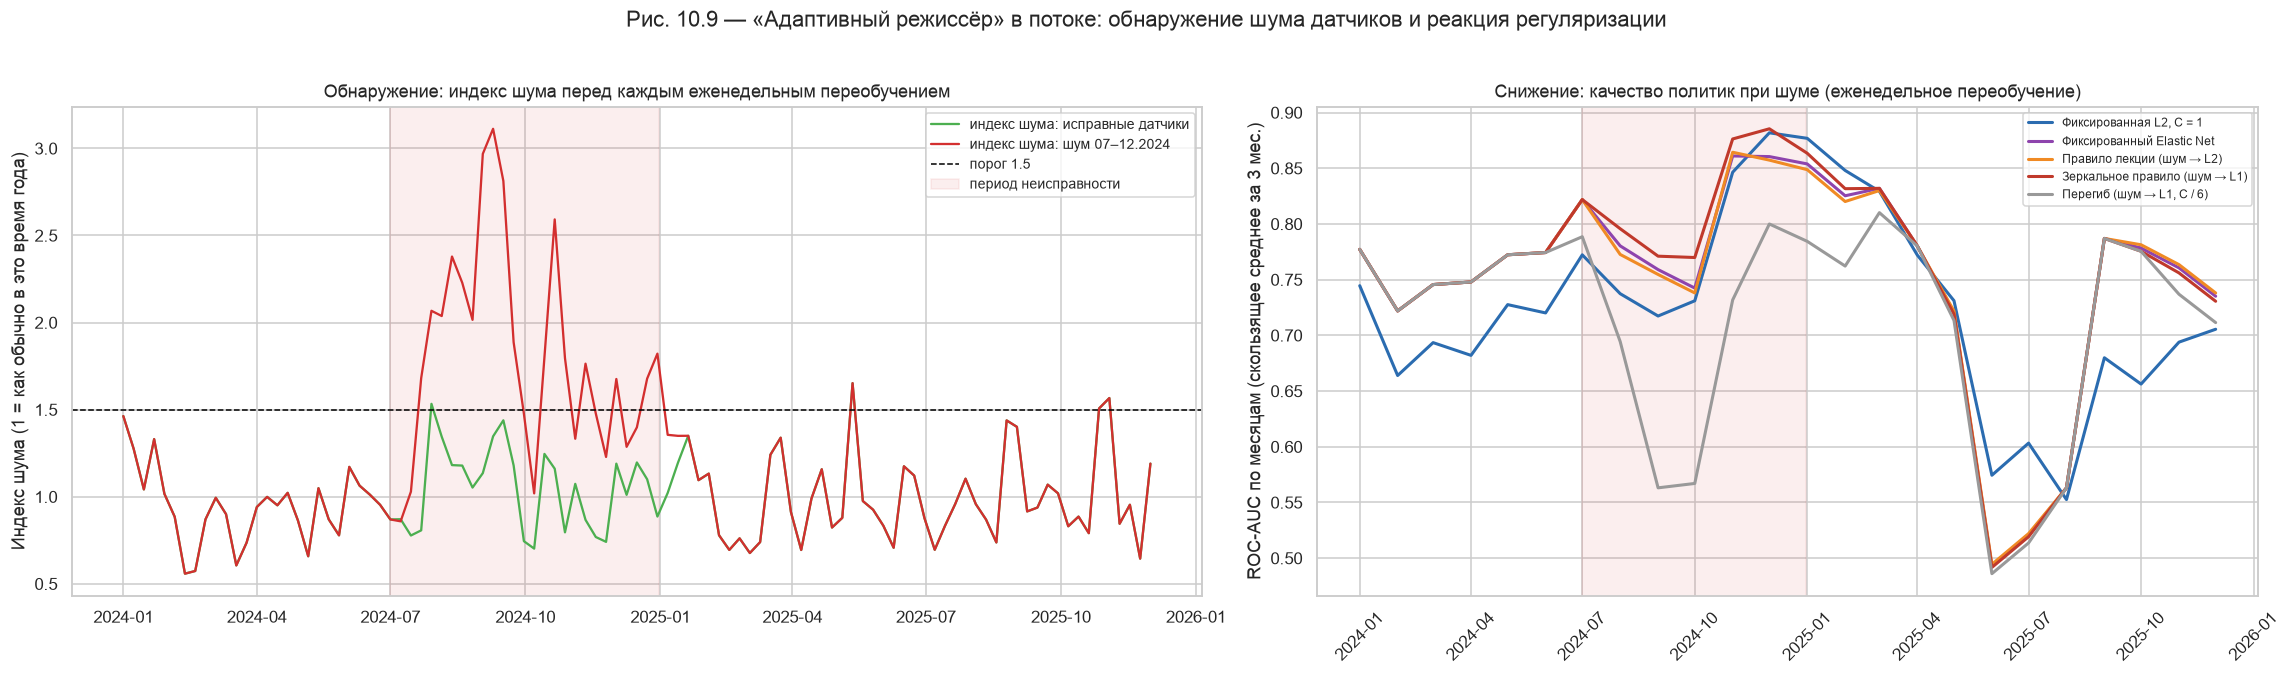

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(21, 6), gridspec_kw={"width_ratios": [1.2, 1]})
for scen, col in [("исправные датчики", "#4CAF50"), ("шум 07–12.2024", "#D32F2F")]:
    LOG = logs[(scen, "еженедельно", "Фиксированный Elastic Net")][1]
    axes[0].plot(LOG.period, LOG.noise_index, color=col, lw=1.5, label=f"индекс шума: {scen}")
axes[0].axhline(1.5, color="black", ls="--", lw=1, label="порог 1.5")
axes[0].axvspan(pd.Timestamp(NOISE_START), pd.Timestamp(NOISE_END), color="#D32F2F", alpha=0.08, label="период неисправности")
axes[0].set(ylabel="Индекс шума (1 = как обычно в это время года)", title="Обнаружение: индекс шума перед каждым еженедельным переобучением")
axes[0].legend(fontsize=9)
pol_cols = ["#2B6CB0", "#8E44AD", "#F08A24", "#C0392B", "#999999"]
for pol_name, col in zip(POLICIES, pol_cols):
    P = logs[("шум 07–12.2024", "еженедельно", pol_name)][0].copy()
    P["month"] = P.date.dt.to_period("M").dt.start_time
    mon = P.groupby("month").apply(lambda g: roc_auc_score(g.y, g.p) if g.y.nunique() > 1 else np.nan)
    axes[1].plot(mon.index, mon.rolling(3, min_periods=1).mean(), color=col, lw=2, label=pol_name)
axes[1].axvspan(pd.Timestamp(NOISE_START), pd.Timestamp(NOISE_END), color="#D32F2F", alpha=0.08)
axes[1].set(ylabel="ROC-AUC по месяцам (скользящее среднее за 3 мес.)", title="Снижение: качество политик при шуме (еженедельное переобучение)")
axes[1].legend(fontsize=8); axes[1].tick_params(axis="x", rotation=45)
fig.suptitle("Рис. 10.9 — «Адаптивный режиссёр» в потоке: обнаружение шума датчиков и реакция регуляризации", y=1.02)
plt.tight_layout(); save("fig_10_9_adaptive_director")

**Интерпретация (рис. 10.8–10.9).**

**Обнаружить.**
- **Индекс шума работает (рис. 10.9, слева).** При неисправности он поднимается до 2–3, при исправных датчиках держится около 1.
- Ложные срабатывания: 1 из 24 ежемесячных и 4 из 101 еженедельной проверки. В период шума: 6 из 24 и 20 из 101 (шум длился 26 недель; первые ~2 недели не видны, пока заполняется 14-дневное окно).
- Сезонный эталон обязателен: без него индекс ложно срабатывал зимой (в прототипе — январь–февраль), потому что зимой погода и так скачет сильнее.

**Смоделировать (рис. 10.8).**
- Устойчивость к шуму определяется прежде всего **силой** штрафа. При шуме 0.5σ на 4 датчиках ROC-AUC падает:
  - при C = 1 — с 0.762 до 0.612–0.614 (все три метода одинаково);
  - при C = 0.1 — до 0.696 (L2) … 0.742 (L1);
  - при C = 0.01 — до 0.754 (L2) … 0.775 (L1 и ENet).
- **Механизм** (правая панель): при слабом штрафе связанные признаки (температура, точка росы, дефицит точки росы = T − Td) получают большие веса разных знаков, которые гасят друг друга на чистых данных. Шум в одном датчике эту компенсацию ломает, и ошибка усиливается многократно. Сильный штраф сжимает такие пары и убирает усиление.
- При равном C L1 и ENet устойчивее L2: они опираются на меньшее число признаков и поэтому меньше «собирают» шум.

**Снизить: проверка правила лекции.**
- Правило «шум → α к L2» на наших данных **немного вредит:** ROC-AUC в период шума 0.807 (ежемесячно) и 0.808 (еженедельно) против 0.815 / 0.816 у неизменного Elastic Net. Сдвиг к L2 возвращает в модель все 26 признаков, в том числе зашумлённые.
- **Зеркальное правило «шум → α к L1 при том же C»** — лучшее: 0.822 (ежемесячно) и 0.831 (еженедельно). Модель на время неисправности сокращается до 8 признаков, а на исправных датчиках правило ничего не портит (0.793 / 0.791 за 2024–2025 при 0.792 у фиксированного ENet). Но по **F1** выигрыша нет (0.571 / 0.583 против 0.574 / 0.594): порог 0.49 подобран на валидации для ENet, а у модели L1 из 8 признаков вероятности распределены иначе. Значит, при смене конфигурации «на лету» нужно менять и порог — держать заранее подобранный порог для каждой конфигурации.
- **«Перегиб»** (L1 и C / 6) обнуляет все признаки: модель выдаёт константу, и ROC-AUC в период шума падает до 0.72. Сильнее — не значит лучше.
- **L2 с C = 1** (настройки по умолчанию из скриптов лекции) при шуме — 0.767 / 0.788: хуже всех разумных вариантов.

**Вывод (сделали X, потому что Y).**
1. **Главная мера** — всегда держать сильную регуляризацию, выбранную по валидации. Это даёт +0.05 ROC-AUC при шуме ещё до всякой адаптации (0.815 против 0.767).
2. **Адаптивный «режиссёр» полезен, но двигать α нужно к L1, а не к L2:** при шуме модели нужно меньше признаков, а не больше. Мы сохраняем идею лекции (α меняется по сигналу о шуме), но направление выбрано по данным.
3. **Еженедельное переобучение реагирует быстрее** (0.831 против 0.822) при цене 2 с вычислений за два года.
4. Регуляризация **не заменяет** ремонта датчика. Индекс шума — это сигнал службе эксплуатации, как и пространственный контроль барометра в ноутбуке 04.

---
# IV. «Вишенка на торте»: SHAP против коэффициентов

Как в `elastic_net_shap.py` / `elastic_net_shap_trio.py`: `shap.LinearExplainer` для трёх моделей (параметры из части II). Для линейной модели с независимыми признаками SHAP имеет точную формулу
$$\phi_j(x) = w_j\,(z_j - \bar z_j),$$
где $z$ — стандартизованный признак, $\bar z$ — его среднее по фону (обучению). Вклад считается в **логит-шкале** (log-odds), а не в вероятности, как у Random Forest в ноутбуке 08. Отвечаем на вопросы лекции: *какой признак влияет сильнее всего?* и *согласуется ли график SHAP с коэффициентами?* Для сравнения — важность по TreeSHAP у Random Forest.

In [15]:
shap_imp, coef_abs, svs = {}, {}, {}
for m_name, b in BEST.items():
    sc, lr = b["model"][0], b["model"][-1]
    Z_tr, Z_te = sc.transform(X_tr), sc.transform(X_te)
    ex = shap.LinearExplainer(lr, shap.maskers.Independent(Z_tr, max_samples=len(Z_tr)))
    sv = ex.shap_values(Z_te); svs[m_name] = sv
    manual = lr.coef_[0] * (Z_te - Z_tr.mean(0))
    shap_imp[m_name] = np.abs(sv).mean(0); coef_abs[m_name] = np.abs(lr.coef_[0])
    print(f"{m_name}: max |SHAP − w·(z − z̄)| = {np.abs(sv - manual).max():.1e}; "
          f"ρ Спирмена (|w|, средний |SHAP|) = {stats.spearmanr(coef_abs[m_name], shap_imp[m_name]).statistic:.3f}")
tree_sv = np.asarray(shap.TreeExplainer(rf).shap_values(X_te)); tree_sv = tree_sv[..., 1] if tree_sv.ndim == 3 else tree_sv
rf_imp = np.abs(tree_sv).mean(0)
imp = pd.DataFrame({**{m: shap_imp[m] for m in METHODS}, "Random Forest (TreeSHAP)": rf_imp}, index=RU)
print("\nСогласие рейтингов важности с Random Forest (ρ Спирмена по 26 признакам):",
      {m: round(stats.spearmanr(shap_imp[m], rf_imp).statistic, 2) for m in METHODS})
top8 = {m: set(imp[m].nlargest(8).index) for m in imp}
print("Общие из 8 главных с Random Forest:", {m: len(top8[m] & top8["Random Forest (TreeSHAP)"]) for m in METHODS})

L1 (Lasso): max |SHAP − w·(z − z̄)| = 0.0e+00; ρ Спирмена (|w|, средний |SHAP|) = 0.979
L2 (Ridge): max |SHAP − w·(z − z̄)| = 0.0e+00; ρ Спирмена (|w|, средний |SHAP|) = 0.966
Elastic Net: max |SHAP − w·(z − z̄)| = 0.0e+00; ρ Спирмена (|w|, средний |SHAP|) = 0.986



Согласие рейтингов важности с Random Forest (ρ Спирмена по 26 признакам): {'L1 (Lasso)': np.float64(0.4), 'L2 (Ridge)': np.float64(0.52), 'Elastic Net': np.float64(0.4)}
Общие из 8 главных с Random Forest: {'L1 (Lasso)': 6, 'L2 (Ridge)': 5, 'Elastic Net': 5}


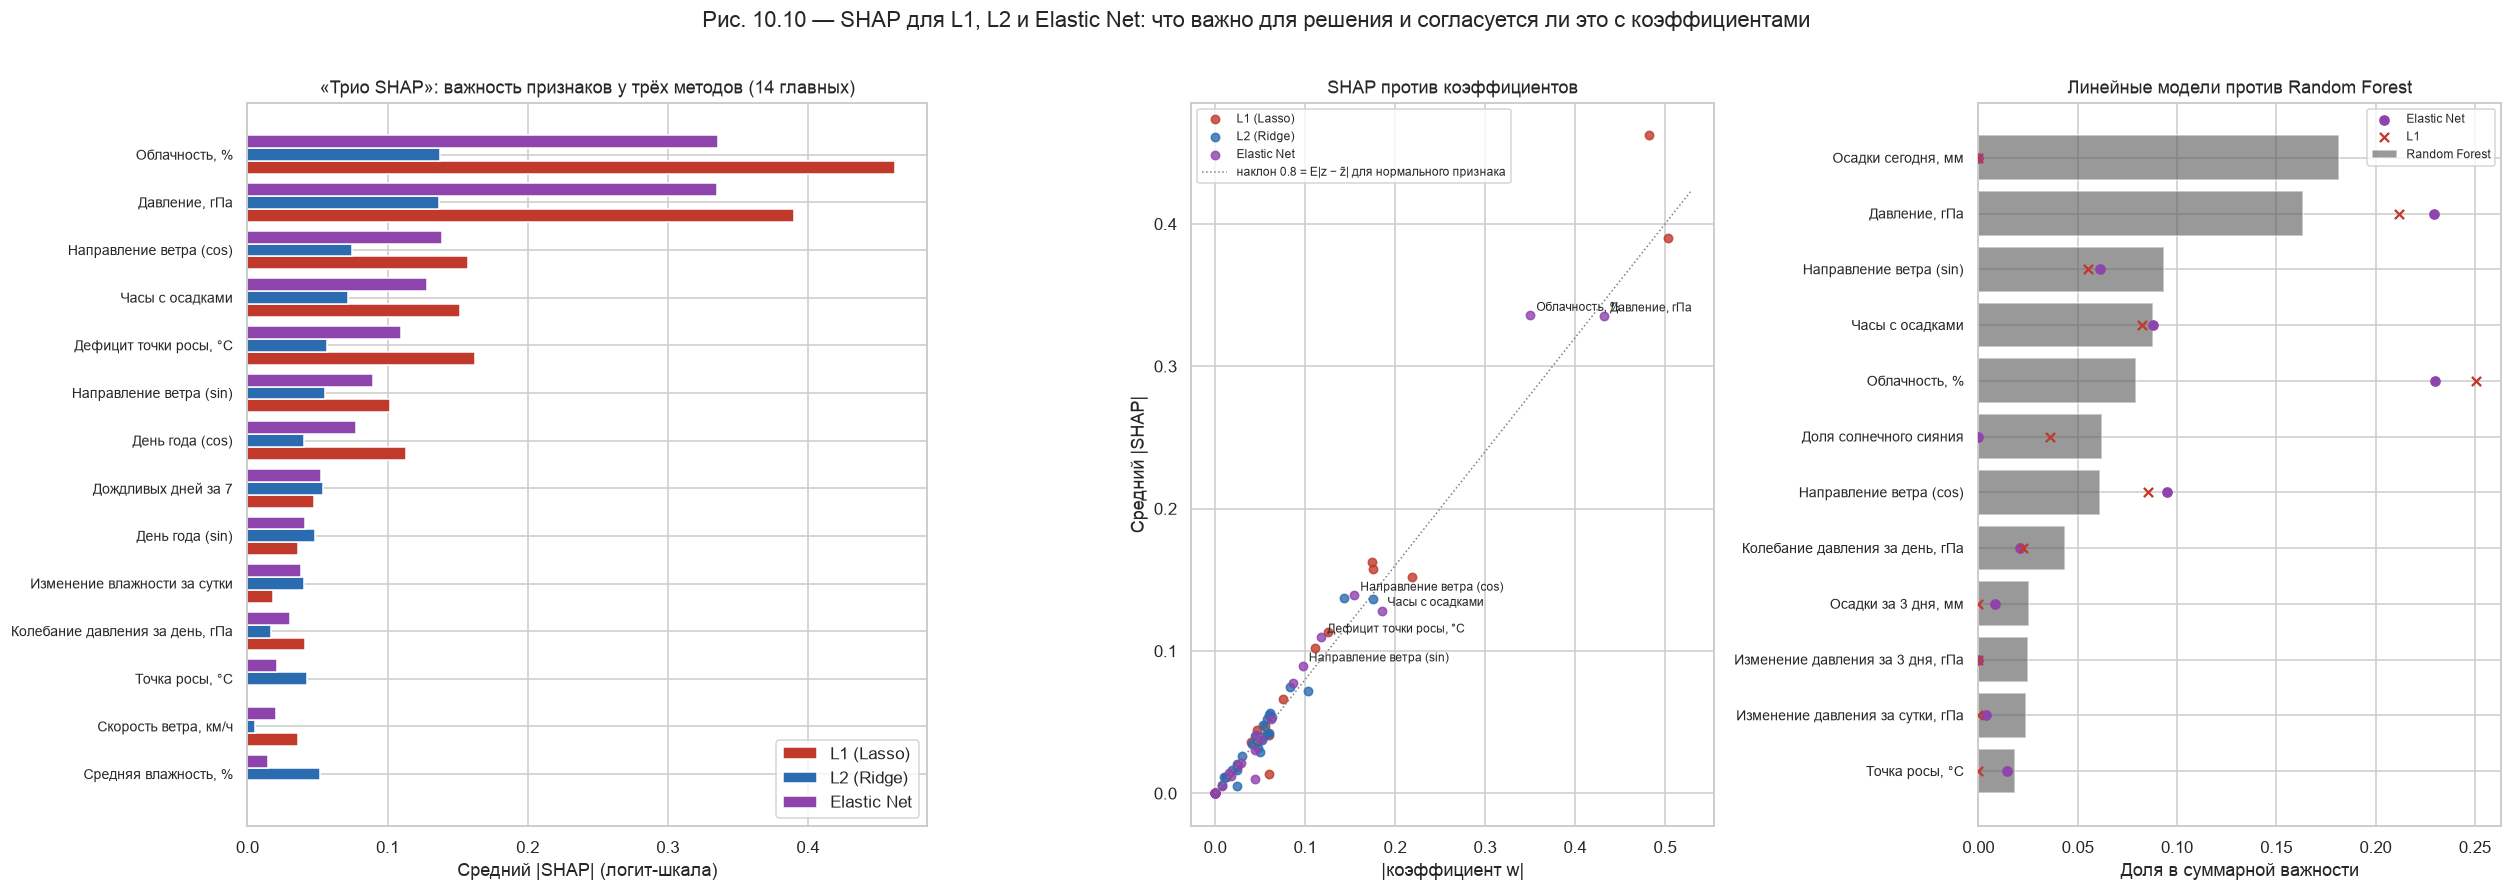

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(23, 8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
order = imp["Elastic Net"].sort_values().index[-14:]
yy = np.arange(len(order))
for k, m_name in enumerate(METHODS):
    axes[0].barh(yy + (k - 1) * 0.27, imp.loc[order, m_name], height=0.27, color=METHOD_COLORS[m_name], label=m_name)
axes[0].set_yticks(yy); axes[0].set_yticklabels(order, fontsize=9)
axes[0].set(xlabel="Средний |SHAP| (логит-шкала)", title="«Трио SHAP»: важность признаков у трёх методов (14 главных)"); axes[0].legend()
for m_name in METHODS:
    axes[1].scatter(coef_abs[m_name], shap_imp[m_name], color=METHOD_COLORS[m_name], s=30, alpha=0.8, label=m_name)
lim = max(max(v.max() for v in coef_abs.values()), max(v.max() for v in shap_imp.values())) * 1.05
axes[1].plot([0, lim], [0, lim * 0.8], color="grey", ls=":", lw=1, label="наклон 0.8 = E|z − z̄| для нормального признака")
for j in np.argsort(-shap_imp["Elastic Net"])[:6]:
    axes[1].annotate(RU[j], (coef_abs["Elastic Net"][j], shap_imp["Elastic Net"][j]), fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[1].set(xlabel="|коэффициент w|", ylabel="Средний |SHAP|", title="SHAP против коэффициентов"); axes[1].legend(fontsize=8)
rel = imp.div(imp.sum(), axis=1)
o2 = rel["Random Forest (TreeSHAP)"].sort_values().index[-12:]
axes[2].barh(o2, rel.loc[o2, "Random Forest (TreeSHAP)"], color="#555555", alpha=0.6, label="Random Forest")
axes[2].scatter(rel.loc[o2, "Elastic Net"], o2, color=METHOD_COLORS["Elastic Net"], zorder=3, label="Elastic Net")
axes[2].scatter(rel.loc[o2, "L1 (Lasso)"], o2, color=METHOD_COLORS["L1 (Lasso)"], marker="x", zorder=3, label="L1")
axes[2].set(xlabel="Доля в суммарной важности", title="Линейные модели против Random Forest"); axes[2].legend(fontsize=8)
axes[2].tick_params(axis="y", labelsize=9)
fig.suptitle("Рис. 10.10 — SHAP для L1, L2 и Elastic Net: что важно для решения и согласуется ли это с коэффициентами", y=1.01)
plt.tight_layout(); save("fig_10_10_shap_vs_coefficients")

**Интерпретация (часть IV, рис. 10.10).**

- **SHAP для линейной модели — это коэффициент × отклонение.** Проверка: |SHAP − w·(z − z̄)| = 0 для всех трёх моделей. Поэтому глобальная важность SHAP почти повторяет |коэффициенты|: ρ Спирмена 0.98 (L1), 0.97 (L2), 0.99 (ENet). Отклонения есть только у признаков с несимметричным распределением (облачность чаще бывает 0 % или 100 %, поэтому её средний |SHAP| ниже, чем «предсказывает» коэффициент).
- **Ответ на вопрос лекции «какой признак влияет сильнее всего?»:** у всех трёх линейных моделей — **облачность и давление** (у ENet по ≈ 0.34 в логит-шкале), затем направление ветра (cos), часы с осадками, дефицит точки росы.
- **Ответ «согласуется ли SHAP с коэффициентами?»** — да, полностью (формула выше). SHAP добавляет **вклад для конкретного дня:** большой коэффициент у признака, который в этот день близок к среднему, почти ничего не вносит.
- **Главное открытие — сравнение с Random Forest (правая панель).** Рейтинги важности согласуются лишь умеренно (ρ 0.40–0.52), хотя 5–6 из 8 главных признаков общие.
  - Самый важный признак Random Forest — **«осадки сегодня»** (18 % важности), а у линейных моделей его вклад почти нулевой.
  - Причина видна в ноутбуке 08 (рис. 9.2): влияние осадков **ступенчатое** — важен сам факт дождя, а дальше рост не помогает. Распределение сильно скошено (больше половины дней — 0 мм). Прямая линия такую зависимость не передаёт, и линейная модель берёт ту же информацию из более «линейного» признака — часов с осадками.
  - Отсюда и разница в PR-AUC (0.551 против 0.51): Random Forest лучше ловит нелинейные пороговые эффекты.
- **Мера:** если линейная модель нужна как быстрая (например, на устройстве станции), добавить признак-индикатор «был дождь сегодня (≥ 1 мм)» — это превращает ступеньку в линейный признак.

---
# V. Мультиклассовая задача: тип погоды завтра

В конце лекции разбирается переход от бинарной цели к нескольким классам: мультиномиальная логистическая регрессия, **F1 macro** и **SHAP по каждому классу**. У преподавателя классы синтетические (случайные метки, F1 macro 0.24 ≈ угадывание). У нас настоящая трёхклассовая цель — **тип погоды завтра**: 0 благоприятная, 1 неблагоприятная, 2 критическая (≈ 7 % дней). Сравниваем три штрафа (C выбирается по F1 macro на валидации) с Random Forest (`class_weight="balanced"`, как в ноутбуке 04).

In [17]:
y3_tr, y3_va, y3_te = train[TARGET3], valid[TARGET3], test[TARGET3].to_numpy()
rows, M3 = [], {}
for m_name, r in METHODS.items():
    best = max(([C, f1_score(y3_va, make_model(C, r).fit(X_tr, y3_tr).predict(X_va), average="macro")] for C in [0.003, 0.01, 0.03, 0.1, 1.0]), key=lambda t: t[1])
    m, fit_ms = fit_timed(make_model(best[0], r), X_tr, y3_tr)
    M3[m_name] = m
    pr = m.predict(X_te); rc = recall_score(y3_te, pr, average=None)
    W = m[-1].coef_
    rows.append({"Модель": m_name, "C": best[0], "F1 macro": f1_score(y3_te, pr, average="macro"), "Recall: благоприятная": rc[0],
                 "Recall: неблагоприятная": rc[1], "Recall: критическая": rc[2], "Ненулевых по классам": " / ".join(str(int((np.abs(w) > 1e-10).sum())) for w in W),
                 "Обучение, мс": fit_ms})
rf3 = clone(rf).set_params(class_weight="balanced").fit(X_tr, y3_tr)
pr = rf3.predict(X_te); rc = recall_score(y3_te, pr, average=None)
rows.append({"Модель": "Random Forest (balanced)", "C": "—", "F1 macro": f1_score(y3_te, pr, average="macro"), "Recall: благоприятная": rc[0],
             "Recall: неблагоприятная": rc[1], "Recall: критическая": rc[2], "Ненулевых по классам": "—", "Обучение, мс": fit_timed(clone(rf3).set_params(n_jobs=1), X_tr, y3_tr)[1]})
multi_tbl = pd.DataFrame(rows)
print("Тест 2024–2025:", dict(zip(WEATHER_TYPES, np.bincount(y3_te))))
multi_tbl.round(3)

Тест 2024–2025: {'Благоприятная': np.int64(405), 'Неблагоприятная': np.int64(268), 'Критическая': np.int64(57)}


,Модель,C,F1 macro,Recall: благоприятная,Recall: неблагоприятная,Recall: критическая,Ненулевых по классам,"Обучение, мс"
0,L1 (Lasso),0.01,0.484,0.642,0.459,0.491,4 / 0 / 6,15.155
1,L2 (Ridge),0.003,0.487,0.644,0.455,0.509,26 / 26 / 26,11.439
2,Elastic Net,0.1,0.482,0.684,0.410,0.491,16 / 10 / 21,232.626
3,Random Forest (balanced),—,0.525,0.728,0.463,0.509,—,2101.542


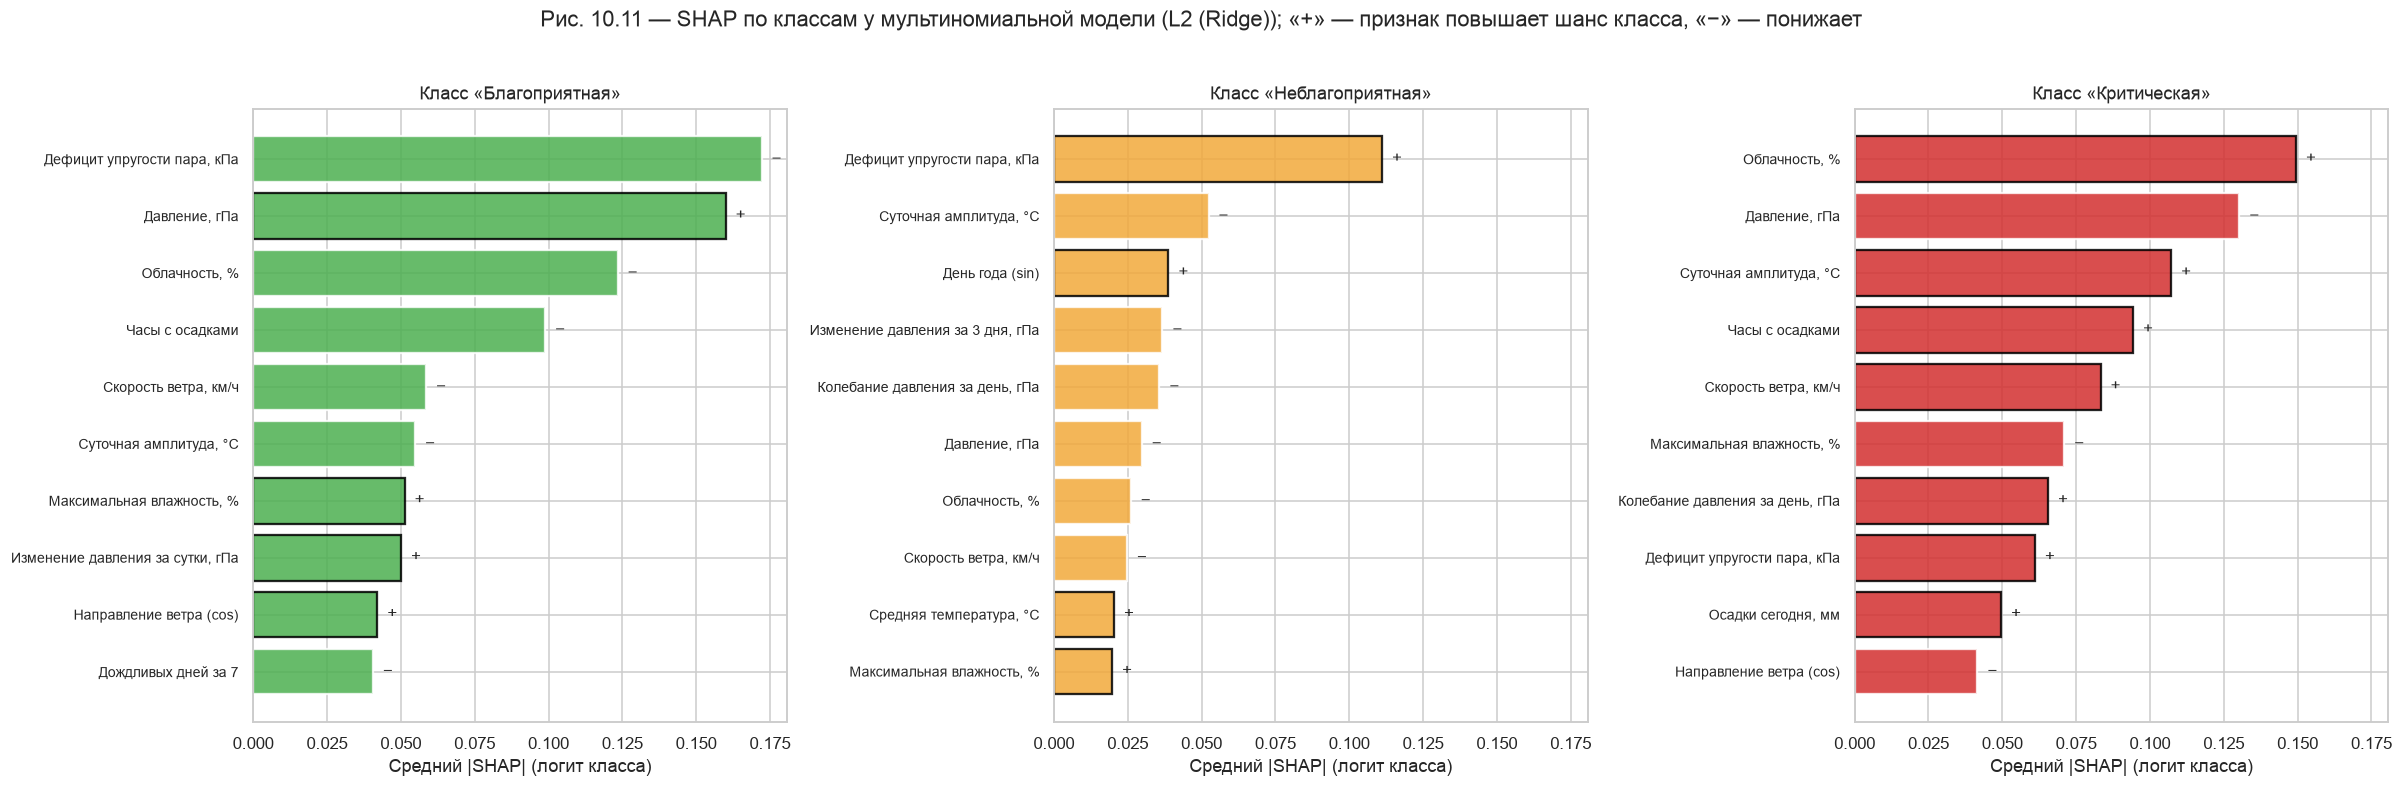

In [18]:
best3 = multi_tbl.iloc[:3].sort_values("F1 macro", ascending=False).iloc[0]["Модель"]
m = M3[best3]; sc, lr = m[0], m[-1]
Z_tr, Z_te = sc.transform(X_tr), sc.transform(X_te)
sv3 = np.asarray(shap.LinearExplainer(lr, shap.maskers.Independent(Z_tr, max_samples=len(Z_tr))).shap_values(Z_te))
sv3 = sv3 if sv3.shape[-1] == 3 else np.moveaxis(sv3, 0, -1)          # (days, features, classes)
fig, axes = plt.subplots(1, 3, figsize=(22, 7), sharex=True)
cols3 = ["#4CAF50", "#F2A93B", "#D32F2F"]
for k, ax in enumerate(axes):
    s = pd.Series(np.abs(sv3[:, :, k]).mean(0), index=RU).sort_values()[-10:]
    sign = pd.Series(lr.coef_[k], index=RU)[s.index]
    ax.barh(s.index, s.values, color=cols3[k], alpha=0.85, edgecolor=np.where(sign > 0, "black", "white"), linewidth=1.5)
    for y_, (f, v) in enumerate(s.items()):
        ax.text(v, y_, "  +" if sign[f] > 0 else "  −", va="center", fontsize=11)
    ax.set(title=f"Класс «{WEATHER_TYPES[k]}»", xlabel="Средний |SHAP| (логит класса)")
    ax.tick_params(axis="y", labelsize=9)
fig.suptitle(f"Рис. 10.11 — SHAP по классам у мультиномиальной модели ({best3}); «+» — признак повышает шанс класса, «−» — понижает", y=1.02)
plt.tight_layout(); save("fig_10_11_multiclass_shap")

**Интерпретация (часть V, рис. 10.11).**

- **Мультиклассовая задача решается заметно лучше случайной:** F1 macro 0.48–0.49 у линейных моделей и 0.525 у Random Forest (у преподавателя на синтетических случайных метках — 0.24, уровень угадывания для 4 классов).
- **Критический класс (57 дней теста, 7.8 %).** Recall 0.509 у L2 — столько же, сколько у Random Forest; у L1 и ENet — 0.491. Благодаря `class_weight="balanced"` редкий класс не теряется (как в ноутбуке 03).
- **L1 в мультиклассе обнуляет целый класс:** у класса «неблагоприятная» 0 ненулевых коэффициентов (4 / 0 / 6 по классам). В мультиномиальной модели класс может определяться «от противного» — через веса двух других классов. Модель становится предельно простой, но менее интерпретируемой по классам. Поэтому для SHAP по классам выбрана L2 (лучший F1 macro).
- **SHAP по классам (рис. 10.11) — у каждого класса свои «голоса»:**
  - **«Благоприятная»:** низкий дефицит упругости пара (нет жары и сухости), высокое давление, малая облачность, нет часов с осадками.
  - **«Неблагоприятная»:** главный голос — **высокий дефицит упругости пара** (жаркие сухие дни ≥ 30 °C тоже неблагоприятные по нашим критериям), затем меньшая суточная амплитуда и сезон.
  - **«Критическая»:** **облачность**, **низкое давление**, большая суточная амплитуда, часы с осадками, **скорость ветра** — признаки активного фронта или грозы.
  - Физически это осмысленно: «неблагоприятная» и «критическая» погода — разные явления (жара против бури), и модель различает их по разным признакам, как и говорится в лекции: *«в мультиклассе каждая метка — оттенок»*.

In [19]:
# results for the report and the app
out = ROOT / "data" / "processed"
pd.concat([part1.assign(Часть="I"), best_tbl.assign(Часть="II")]).to_csv(out / "regularization_models.csv", index=False)
stream_tbl.to_csv(out / "regularization_stream.csv", index=False)
noise_tbl.to_csv(out / "regularization_noise_policies.csv", index=False)
pd.concat([logs[k][1].assign(Датчики=k[0], Переобучение=k[1], Политика=k[2]) for k in logs]).to_csv(out / "regularization_noise_log.csv", index=False)
joblib.dump({m: {"C": b["C"], "l1_ratio": b["α"], "threshold": b["thr"]} for m, b in BEST.items()}, ROOT / "models" / "regularization_best.joblib")
print("Сохранено: data/processed/regularization_*.csv, models/regularization_best.joblib")

Сохранено: data/processed/regularization_*.csv, models/regularization_best.joblib


---
# Вердикт и ответы на вопросы лекции 4

### Кому доверить поток? Выбор метода для сценариев (часть IV лекции)

| Сценарий | Метод | Обоснование (наши цифры) |
|---|---|---|
| **Поток в реальном времени с жёсткой латентностью** (тысячи станций, записи каждые 10 мин, расчёт на самой станции) | **Elastic Net / L1 при сильном штрафе** | прогноз записи 0.3 мс (Random Forest 7.2 мс), 24 переобучения за 0.4–0.5 с (Random Forest 65 с); ROC-AUC 0.79 ≈ Random Forest; 6–17 признаков → нужно меньше датчиков |
| **Разбор после события, максимум деталей** | **Random Forest + SHAP** (и L2 для обзора всех 26 признаков) | лучший PR-AUC 0.551, видит нелинейность «осадков сегодня»; латентность не важна; L2 показывает вклад каждого признака без отсечения |
| **Адаптивная система с меняющимися условиями** (деградация датчиков, сдвиг климата) | **Elastic Net (C по валидации) + индекс шума; при шуме α → 1 (L1) при том же C** | при шуме ROC-AUC 0.831 против 0.808 у правила лекции и 0.788 у L2 с C = 1; без шума качество не страдает |
| **Наша станция (1 запись в сутки)** | **Random Forest** — основная модель, **Elastic Net** — быстрый резерв и «второе мнение» | латентность не ограничивает (7 мс в сутки), а PR-AUC и F1 в потоке у Random Forest не хуже; ENet нужен при масштабировании и как контроль: если две модели резко расходятся, проверить данные |

### Ответы на вопросы этапов лабораторной

1. **Какие различия вы видите между коэффициентами L1, L2 и ENet?** — При C = 1 различий практически нет (штраф слабый). При сильном штрафе L1 оставляет 6–15 признаков и обнуляет остальные, L2 оставляет все 26, но уменьшает их, ENet оставляет 14–17 признаков группами (рис. 10.1, 10.3). Знаки главных весов у всех одинаковы: давление «−», облачность и часы с осадками «+».
2. **Какой признак сильнее всего влияет на решение?** — По SHAP у линейных моделей — облачность и давление (≈ 0.34 в логит-шкале у ENet), у Random Forest — осадки сегодня и давление (рис. 10.10).
3. **Как график SHAP соотносится с коэффициентами? Согласованы ли они?** — Да: для линейной модели SHAP = w·(z − z̄) точно, ρ Спирмена 0.97–0.99. SHAP добавляет вклад конкретного дня и единую шкалу для сравнения с нелинейными моделями (у Random Forest коэффициентов нет).

### Вопросы рефлексии

1. **Что означают положительные и отрицательные коэффициенты?** — Знак показывает направление: «+» — рост признака на одно стандартное отклонение увеличивает логарифм шансов дождя (облачность +0.33 у ENet → шансы × e^0.33 ≈ 1.4), «−» — уменьшает (давление −0.43 → шансы × 0.65). Сравнивать величины можно только потому, что признаки стандартизованы; при сильной связи признаков (дефицит точки росы = T − Td) отдельный коэффициент толковать нельзя — веса делят между собой общий вклад.
2. **Чем различаются L1, L2 и ENet по способу штрафа?** — L1 штрафует сумму модулей (угловая граница → точные нули, отбор признаков), L2 — сумму квадратов (гладкая граница → все веса уменьшаются, но не обнуляются, лучше при связанных признаках), ENet — взвешенную сумму обоих (α = доля L1).
3. **Что SHAP даёт сверх коэффициентов?** — Вклад для каждого дня, а не только «в среднем»; аддитивность (база + сумма вкладов = прогноз); одинаковый язык для линейных и нелинейных моделей. Именно сравнение SHAP линейной модели и Random Forest показало, что линейная модель не «видит» ступенчатое влияние осадков сегодня.
4. **Как объяснить коллеге, почему интерпретируемость важна?** — В этом ноутбуке интерпретация трижды изменила решение: (1) коэффициенты разных знаков у связанных признаков объяснили, почему модель с C = 1 рушится при шуме; (2) SHAP показал, чего не хватает линейной модели (признак «был дождь»); (3) нестабильность отбора L1 предостерегла от вывода «эти 6 признаков — физически главные». Без интерпретации у нас были бы только цифры качества, и все три ошибки остались бы незамеченными.

### Связь с прежними темами (как в лекции: noise, bias, variance)

| Тема | Что показал ноутбук 09 |
|---|---|
| **Noise** (ноутб. 03, 05, 06) | при шуме датчиков решает сила регуляризации; слабый штраф + связанные признаки многократно усиливают шум |
| **Bias** | слишком сильный штраф (C ≤ 0.002 у L1) обнуляет модель — крайний случай недообучения; линейная форма даёт bias на нелинейных признаках (осадки сегодня) |
| **Variance** | L2 стабилизирует веса (разброс 0.21 против 0.42 у L1), но отбор признаков L1 нестабилен (9 признаков); стабильность в потоке ≠ стабильность на другой истории |
| **Streaming / RTAP** (ноутб. 04) | переобучение микропакетами меняет веса плавно (≈ 2 % в месяц); адаптация α по индексу шума — ещё одно автоматическое вмешательство RTAP |
| **XAI** (ноутб. 08) | SHAP линейной модели = коэффициент × отклонение; сравнение с TreeSHAP выявило нелинейность |

### Обнаружить → смоделировать → снизить (итог)

| Фактор | Обнаружили | Смоделировали | Снизили |
|---|---|---|---|
| Связанные признаки (T, Td, T − Td) | большие веса разных знаков при C = 1 (рис. 10.1) | шум 0.5σ на 4 датчиках: ROC-AUC 0.762 → 0.614 | сильный штраф по валидации: 0.775 при том же шуме |
| Шум датчиков в потоке | индекс шума с сезонным эталоном (ложных срабатываний 4 из 101) | неисправность 07–12.2024 | α → L1 при шуме: 0.831 против 0.816 (фикс.) и 0.808 (правило лекции) |
| Нестабильный отбор L1 | бутстрэп: 9 признаков в 20–80 % выборок | 30 разных «историй» | ENet / стабильный отбор (≥ 80 % выборок) |
| Нелинейность «осадков сегодня» | SHAP: у линейных моделей ≈ 0, у Random Forest — № 1 | — | Random Forest остаётся основной моделью; для линейной — индикатор «был дождь» |

> **Для меня регуляризация — это** умение модели не верить каждому шёпоту данных. На наших данных главным оказался не выбор «скульптора» или «художника», а **сила** штрафа: правильно подобранная, она делает простую модель почти такой же точной, как лес из 400 деревьев, в 25 раз быстрее и заметно устойчивее к сломанным датчикам.